# CICIoT2023 Dataset Exploration & Analysis

**Diploma Thesis** - IoT/IoMT Network Intrusion Detection  
**Dataset**: CICIoT2023 — A Real-Time Dataset and Benchmark for Large-Scale Attacks in IoT Environment  
**Paper**: Neto et al. (2023), *Sensors*, 23(13), 5941  

---

## Table of Contents

1. **Methodology & Dataset Description** — How it was created, topology, tools
2. **Data Loading** — Reading CSV files with sampling
3. **Basic Statistics** — Shape, dtypes, null values, duplicates
4. **Feature Analysis** — Categorization, distributions, correlations
5. **Label Analysis** — Distribution of categories (binary / 8-class / 34-class)
6. **Window-based Aggregation** — Understanding aggregation at 10 & 100 packets
7. **Conclusions & Key Findings**

## 1. Methodology & Dataset Description

### 1.1 Overview

**CICIoT2023** was created by the Canadian Institute for Cybersecurity (CIC) at the University of New Brunswick.

| Characteristic | Value |
|---|---|
| **Number of attacks** | 33 (in 7 categories) |
| **Devices** | 105 IoT (67 directly involved + 38 Zigbee/Z-Wave) |
| **Topology** | Smart home — realistic |
| **Capture** | Wireshark + Gigamon Network Tap (full-duplex) |
| **Formats** | PCAP (~548 GB) & CSV (flow-level features) |
| **Feature extraction** | DPKT package, window-based aggregation |
| **Number of features (CSV)** | 39 + Label |
| **Total records** | ~44.8 million (63 CSV files, ~9.1 GB) |

### 1.2 Attack Categories (7 categories, 33 attacks)

| Category | Number of Attacks | Examples | Rows (paper) |
|---|---|---|---|
| **DDoS** | 12 | SYN/TCP/UDP/ICMP/HTTP Flood, SlowLoris, ACK/UDP/ICMP Frag, SynonymousIP | ~34.0M |
| **DoS** | 4 | SYN/TCP/UDP/HTTP Flood | ~8.1M |
| **Mirai** | 3 | GREIP, Greeth, UDPPlain | ~2.6M |
| **Benign** | 1 | Normal traffic | ~1.1M |
| **Spoofing** | 2 | ARP Spoofing, DNS Spoofing | ~0.5M |
| **Recon** | 5 | Ping Sweep, OS/Port/Vuln Scan, Host Discovery | ~0.35M |
| **Web-based** | 6 | SQL Injection, XSS, Backdoor, Command Injection, Upload, Browser Hijacking | ~0.025M |
| **Brute Force** | 1 | Dictionary Brute Force | ~0.013M |

### 1.3 Topology

- **Attackers**: 7 Raspberry Pi 4 (2/4/8 GB) — attack via SSH master-client
- **Victims**: Cameras, speakers, smart plugs, sensors, hubs etc.
- **Network**: ASUS Router → Cisco Switch → Gigamon Network Tap → Netgear Switch → IoT devices
- **Capture**: 2 monitoring ports → 2 computers (Wireshark) → mergecap → unified pcap files

### 1.4 Feature Extraction & Window Aggregation

Features were extracted from pcap files using **DPKT** and grouped into windows:
- **Window of 10 packets**: For attacks with low traffic (Web-based, Recon, Spoofing, Benign, Brute Force)
- **Window of 100 packets**: For attacks with high volume (DDoS, DoS, Mirai)

The values of each window are the **mean** of the packets in the window.

> **Note**: The paper (Table 4) describes 46 features, but the actual CSV files (MERGED_CSV)  
> contain **39 features + Label** (40 columns). Some features (e.g. `flow_duration`, `Srate`, `Drate`,  
> `urg_count`, `Magnitue`, `Radius`, `Covariance`, `Weight`) **do not exist** in the merged CSVs.  
> Instead, `IGMP` and `Time_To_Live` (instead of `Duration`) are present.

## 2. Data Loading

We use two loading phases:
1. **Phase 1**: Load only the `Label` column from **all** files → complete label distribution
2. **Phase 2**: **Stratified sample** (~2M rows) → representative sample for feature analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, HTML
import json
import warnings
warnings.filterwarnings('ignore')

# Display settings
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


In [2]:
# ---------------------------------------------------------------------------
# CSV files and basic information
# ---------------------------------------------------------------------------
DATA_DIR = Path("../data/raw/CICIoT2023")
csv_files = sorted(DATA_DIR.glob("Merged*.csv"))

print(f"Directory: {DATA_DIR.resolve()}")
print(f"Number of CSV files: {len(csv_files)}")
print(f"\nFiles:")
for f in csv_files:
    size_mb = f.stat().st_size / (1024**2)
    print(f"  {f.name:20s} — {size_mb:7.1f} MB")

total_size_gb = sum(f.stat().st_size for f in csv_files) / (1024**3)
print(f"\nTotal size: {total_size_gb:.2f} GB")

Directory: /Users/pantelos/Documents/diploma_thesis/data/raw/CICIoT2023
Number of CSV files: 63

Files:
  Merged01.csv         —   140.3 MB
  Merged02.csv         —   147.5 MB
  Merged03.csv         —   137.4 MB
  Merged04.csv         —   133.3 MB
  Merged05.csv         —   146.7 MB
  Merged06.csv         —   141.5 MB
  Merged07.csv         —   138.4 MB
  Merged08.csv         —   140.3 MB
  Merged09.csv         —   133.7 MB
  Merged10.csv         —   180.5 MB
  Merged11.csv         —   179.2 MB
  Merged12.csv         —   176.7 MB
  Merged13.csv         —   139.9 MB
  Merged14.csv         —   177.9 MB
  Merged15.csv         —   141.5 MB
  Merged16.csv         —   150.8 MB
  Merged17.csv         —   144.1 MB
  Merged18.csv         —   140.7 MB
  Merged19.csv         —   138.3 MB
  Merged20.csv         —   141.8 MB
  Merged21.csv         —   136.5 MB
  Merged22.csv         —   145.7 MB
  Merged23.csv         —   135.6 MB
  Merged24.csv         —   146.4 MB
  Merged25.csv         —   138.0

In [3]:
# ---------------------------------------------------------------------------
# Check column consistency across all files
# ---------------------------------------------------------------------------
print("Checking headers across all files...")
headers = {}
for f in csv_files:
    cols = list(pd.read_csv(f, nrows=0).columns)
    key = tuple(cols)
    if key not in headers:
        headers[key] = []
    headers[key].append(f.name)

if len(headers) == 1:
    columns = list(list(headers.keys())[0])
    print(f"✓ All {len(csv_files)} files have IDENTICAL columns ({len(columns)} columns)")
    print(f"\nColumns:")
    for i, col in enumerate(columns, 1):
        print(f"  {i:2d}. {col}")
else:
    print(f"⚠ Found {len(headers)} different schemas!")
    for cols, files in headers.items():
        print(f"\n  Schema ({len(cols)} columns) → {len(files)} files")
        print(f"    Columns: {list(cols)}")
        print(f"    Files: {files[:5]}...")

Checking headers across all files...
✓ All 63 files have IDENTICAL columns (40 columns)

Columns:
   1. Header_Length
   2. Protocol Type
   3. Time_To_Live
   4. Rate
   5. fin_flag_number
   6. syn_flag_number
   7. rst_flag_number
   8. psh_flag_number
   9. ack_flag_number
  10. ece_flag_number
  11. cwr_flag_number
  12. ack_count
  13. syn_count
  14. fin_count
  15. rst_count
  16. HTTP
  17. HTTPS
  18. DNS
  19. Telnet
  20. SMTP
  21. SSH
  22. IRC
  23. TCP
  24. UDP
  25. DHCP
  26. ARP
  27. ICMP
  28. IGMP
  29. IPv
  30. LLC
  31. Tot sum
  32. Min
  33. Max
  34. AVG
  35. Std
  36. Tot size
  37. IAT
  38. Number
  39. Variance
  40. Label


In [4]:
# ---------------------------------------------------------------------------
# Phase 1: Load only Label column → complete label distribution
# ---------------------------------------------------------------------------
print("Phase 1: Loading Labels from all files...")

label_counts_list = []
file_row_counts = {}

for i, f in enumerate(csv_files):
    labels_df = pd.read_csv(f, usecols=['Label'])
    n_rows = len(labels_df)
    file_row_counts[f.name] = n_rows
    counts = labels_df['Label'].value_counts()
    label_counts_list.append(counts)
    if (i + 1) % 10 == 0 or (i + 1) == len(csv_files):
        print(f"  {i + 1}/{len(csv_files)} files...")

# Combine all label counts
full_label_counts = pd.concat(label_counts_list).groupby(level=0).sum().sort_values(ascending=False)
total_rows = sum(file_row_counts.values())

print(f"\n{'='*60}")
print(f"Total records: {total_rows:,}")
print(f"Unique labels: {len(full_label_counts)}")
print(f"\nRecords per file:")
for fname, count in sorted(file_row_counts.items()):
    print(f"  {fname:20s} — {count:>10,} rows")

Phase 1: Loading Labels from all files...


  10/63 files...


  20/63 files...


  30/63 files...


  40/63 files...


  50/63 files...


  60/63 files...


  63/63 files...

Total records: 44,763,144
Unique labels: 34

Records per file:
  Merged01.csv         —    712,311 rows
  Merged02.csv         —    748,585 rows
  Merged03.csv         —    697,289 rows
  Merged04.csv         —    676,620 rows
  Merged05.csv         —    744,804 rows
  Merged06.csv         —    718,229 rows
  Merged07.csv         —    702,212 rows
  Merged08.csv         —    712,220 rows
  Merged09.csv         —    678,882 rows
  Merged10.csv         —    916,190 rows
  Merged11.csv         —    909,761 rows
  Merged12.csv         —    896,941 rows
  Merged13.csv         —    709,937 rows
  Merged14.csv         —    902,920 rows
  Merged15.csv         —    718,483 rows
  Merged16.csv         —    765,369 rows
  Merged17.csv         —    731,532 rows
  Merged18.csv         —    714,063 rows
  Merged19.csv         —    701,978 rows
  Merged20.csv         —    719,927 rows
  Merged21.csv         —    692,566 rows
  Merged22.csv         —    739,382 rows
  Merged23.csv   

In [5]:
# ---------------------------------------------------------------------------
# Phase 2: Stratified Sample (~2M rows) for feature analysis
# ---------------------------------------------------------------------------
SAMPLE_SIZE = 2_000_000

print(f"Loading stratified sample (~{SAMPLE_SIZE:,} rows)...")

# Calculate how many rows to sample from each file (proportional)
sample_frac = SAMPLE_SIZE / total_rows
dfs = []

for i, f in enumerate(csv_files):
    df_chunk = pd.read_csv(f)
    # Sample proportionally from each file
    n_sample = max(1, int(len(df_chunk) * sample_frac))
    df_sampled = df_chunk.sample(n=min(n_sample, len(df_chunk)), random_state=42)
    dfs.append(df_sampled)
    if (i + 1) % 10 == 0 or (i + 1) == len(csv_files):
        print(f"  {i + 1}/{len(csv_files)} files...")

df = pd.concat(dfs, ignore_index=True)
del dfs

# Replace infinity values with NaN (e.g. Rate column has inf)
numeric_cols_tmp = df.select_dtypes(include=[np.number]).columns
inf_replaced = np.isinf(df[numeric_cols_tmp]).sum().sum()
df[numeric_cols_tmp] = df[numeric_cols_tmp].replace([np.inf, -np.inf], np.nan)

print(f"\nSample shape: {df.shape}")
print(f"Sample memory: {df.memory_usage(deep=True).sum() / (1024**2):.1f} MB")
print(f"Sample labels: {df['Label'].nunique()} unique")
if inf_replaced > 0:
    print(f"Infinity values replaced with NaN: {inf_replaced}")

Loading stratified sample (~2,000,000 rows)...


  10/63 files...


  20/63 files...


  30/63 files...


  40/63 files...


  50/63 files...


  60/63 files...


  63/63 files...



Sample shape: (1999973, 40)
Sample memory: 717.7 MB
Sample labels: 34 unique
Infinity values replaced with NaN: 35


## 3. Basic Statistics

In [6]:
# ---------------------------------------------------------------------------
# 3.1 Basic sample information
# ---------------------------------------------------------------------------
print("=" * 60)
print("BASIC STATISTICS (Sample)")
print("=" * 60)

print(f"\nShape: {df.shape}")
print(f"Columns: {df.shape[1]}")
print(f"Records (sample): {df.shape[0]:,}")
print(f"Records (total): {total_rows:,}")
print(f"Memory: {df.memory_usage(deep=True).sum() / (1024**2):.1f} MB")

print(f"\n--- Data Types ---")
print(df.dtypes.value_counts())

print(f"\n--- Columns by type ---")
for dtype in df.dtypes.unique():
    cols = df.select_dtypes(include=[dtype]).columns.tolist()
    print(f"\n  {dtype} ({len(cols)} columns):")
    for c in cols:
        print(f"    - {c}")

BASIC STATISTICS (Sample)

Shape: (1999973, 40)
Columns: 40
Records (sample): 1,999,973
Records (total): 44,763,144
Memory: 717.7 MB

--- Data Types ---
float64    38
int64       1
object      1
Name: count, dtype: int64

--- Columns by type ---



  float64 (38 columns):
    - Header_Length
    - Time_To_Live
    - Rate
    - fin_flag_number
    - syn_flag_number
    - rst_flag_number
    - psh_flag_number
    - ack_flag_number
    - ece_flag_number
    - cwr_flag_number
    - ack_count
    - syn_count
    - fin_count
    - rst_count
    - HTTP
    - HTTPS
    - DNS
    - Telnet
    - SMTP
    - SSH
    - IRC
    - TCP
    - UDP
    - DHCP
    - ARP
    - ICMP
    - IGMP
    - IPv
    - LLC
    - Tot sum
    - Min
    - Max
    - AVG
    - Std
    - Tot size
    - IAT
    - Number
    - Variance

  int64 (1 columns):
    - Protocol Type

  object (1 columns):
    - Label


In [7]:
# ---------------------------------------------------------------------------
# 3.2 Null & Infinity values analysis
# ---------------------------------------------------------------------------
print("=" * 60)
print("NULL & DATA QUALITY ANALYSIS")
print("=" * 60)

null_counts = df.isnull().sum()
null_pct = (null_counts / len(df) * 100).round(2)

null_summary = pd.DataFrame({
    'Null Count': null_counts,
    'Null %': null_pct,
    'Dtype': df.dtypes
})

# Show only columns with nulls
null_cols = null_summary[null_summary['Null Count'] > 0]
if len(null_cols) > 0:
    print(f"\nColumns with null values ({len(null_cols)}):")
    display(null_cols.sort_values('Null Count', ascending=False))
else:
    print("\n✓ No column has null values (after inf→NaN transformation)")

print(f"\nTotal null values: {null_counts.sum():,}")
print(f"  (includes {inf_replaced} infinity values converted to NaN)")

# Duplicate check
n_dupes = df.duplicated().sum()
print(f"\nDuplicate rows: {n_dupes:,} ({n_dupes/len(df)*100:.2f}%)")

NULL & DATA QUALITY ANALYSIS

Columns with null values (3):


,Null Count,Null %,Dtype
Rate,35,0.0,float64
Std,17,0.0,float64
Variance,17,0.0,float64



Total null values: 69
  (includes 35 infinity values converted to NaN)



Duplicate rows: 666,682 (33.33%)


In [8]:
# ---------------------------------------------------------------------------
# 3.3 Descriptive statistics
# ---------------------------------------------------------------------------
print("=" * 60)
print("DESCRIPTIVE STATISTICS (numeric columns)")
print("=" * 60)

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumeric columns: {len(numeric_cols)}")
display(df[numeric_cols].describe().T.round(4))

DESCRIPTIVE STATISTICS (numeric columns)

Numeric columns: 39


,count,mean,std,min,25%,50%,75%,max
Header_Length,1999973.0,13.7228,8.7320,0.0,8.0000,20.0000,20.0000,6.000000e+01
Protocol Type,1999973.0,9.0955,9.1119,0.0,6.0000,6.0000,17.0000,4.700000e+01
Time_To_Live,1999973.0,66.5356,14.4440,0.0,64.0000,64.0000,64.0000,2.550000e+02
Rate,1999938.0,28400.7713,30797.2863,0.0,11357.1363,24569.7616,37978.1239,6.291456e+06
fin_flag_number,1999973.0,0.0868,0.2792,0.0,0.0000,0.0000,0.0000,1.000000e+00
syn_flag_number,1999973.0,0.2061,0.3992,0.0,0.0000,0.0000,0.0100,1.000000e+00
rst_flag_number,1999973.0,0.0929,0.2832,0.0,0.0000,0.0000,0.0000,1.000000e+00
psh_flag_number,1999973.0,0.0939,0.2769,0.0,0.0000,0.0000,0.0000,1.000000e+00
ack_flag_number,1999973.0,0.1298,0.3166,0.0,0.0000,0.0000,0.0100,1.000000e+00
ece_flag_number,1999973.0,0.0000,0.0019,0.0,0.0000,0.0000,0.0000,7.000000e-01


In [9]:
# ---------------------------------------------------------------------------
# 3.4 First and last rows
# ---------------------------------------------------------------------------
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label
0,1.56,47,66.34,1710.041382,0.0,0.02,0.0,0.02,0.03,0.0,0.0,3.0,2.0,0.0,0.0,0.04,0.0,0.04,0.0,0.0,0.0,0.0,0.05,0.04,0.0,0.01,0.0,0.0,0.99,0.99,54265.0,60.0,592.0,542.65,150.282520,542.65,0.000589,100.0,22584.835859,MIRAI-GREETH_FLOOD
1,25.60,6,74.60,78.722808,0.0,0.10,0.0,0.40,0.70,0.0,0.0,7.0,1.0,0.0,0.0,0.10,0.0,0.10,0.0,0.0,0.0,0.0,0.80,0.20,0.0,0.00,0.0,0.0,1.00,1.00,3447.0,66.0,1342.0,344.70,516.549460,344.70,0.013571,10.0,266823.344444,VULNERABILITYSCAN
2,20.00,6,64.00,19466.740926,0.0,1.00,0.0,0.00,0.00,0.0,0.0,0.0,100.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,1.00,0.00,0.0,0.00,0.0,0.0,1.00,1.00,6000.0,60.0,60.0,60.00,0.000000,60.00,0.000051,100.0,0.000000,DOS-SYN_FLOOD
3,8.00,17,62.91,10520.741465,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.00,1.00,0.0,0.00,0.0,0.0,1.00,1.00,7378.0,60.0,794.0,73.78,96.889772,73.78,0.000095,100.0,9387.627879,DOS-UDP_FLOOD
4,19.28,6,65.06,4659.612949,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.94,0.06,0.0,0.00,0.0,0.0,1.00,1.00,17028.0,66.0,230.0,170.28,22.116350,170.28,0.000215,100.0,489.132929,DDOS-TCP_FLOOD



Last 5 rows:


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label
1999968,8.0,17,64.0,26788.682378,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,6000.0,60.0,60.0,60.0,0.0,60.0,0.000037,100.0,0.0,DOS-UDP_FLOOD
1999969,20.0,6,64.0,94615.474848,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,6000.0,60.0,60.0,60.0,0.0,60.0,0.000011,100.0,0.0,DDOS-RSTFINFLOOD
1999970,21.2,6,97.5,610.649041,0.0,0.3,0.7,0.0,0.7,0.0,0.0,7.0,3.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,600.0,60.0,60.0,60.0,0.0,60.0,0.001667,10.0,0.0,RECON-HOSTDISCOVERY
1999971,8.0,17,64.0,25277.550774,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,6000.0,60.0,60.0,60.0,0.0,60.0,0.000040,100.0,0.0,DDOS-UDP_FLOOD
1999972,20.0,6,64.0,14967.896653,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,6000.0,60.0,60.0,60.0,0.0,60.0,0.000067,100.0,0.0,DOS-TCP_FLOOD


## 4. Feature Analysis

### 4.1 Feature Categorization

Based on the paper and the actual data, the 39 features are categorized as follows:

| Category | Features |
|---|---|
| **Header/Protocol** | `Header_Length`, `Protocol Type`, `Time_To_Live`, `HTTPS`, `DNS`, `Telnet`, `SMTP`, `SSH`, `IRC`, `TCP`, `UDP`, `DHCP`, `ARP`, `ICMP`, `IPv`, `LLC`, `IGMP` |
| **Packet Size** | `Tot size`, `IAT`, `Number`, `Tot sum`, `Min`, `Max`, `AVG`, `Std`, `Variance` |
| **Rate/Ratio** | `Rate`, `fin_flag_number`, `syn_flag_number`, `rst_flag_number`, `psh_flag_number`, `ack_flag_number`, `ece_flag_number`, `cwr_flag_number`, `HTTP`, `Magnitue`, `Radius`, `Covariance`, `Weight` |

> **Note**: The above reflect the actual features in the CSVs. Some (Magnitue, Radius etc.) may not exist.

In [10]:
# ---------------------------------------------------------------------------
# 4.1 Feature categorization (actual 39 features)
# ---------------------------------------------------------------------------

# Define categories based on actual columns
feature_groups = {
    'Protocol Flags': [c for c in ['HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 
                                     'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC',
                                     'IGMP', 'HTTP'] if c in df.columns],
    'TCP Flags': [c for c in ['fin_flag_number', 'syn_flag_number', 'rst_flag_number',
                               'psh_flag_number', 'ack_flag_number', 'ece_flag_number',
                               'cwr_flag_number'] if c in df.columns],
    'Packet/Flow Stats': [c for c in ['Header_Length', 'Protocol Type', 'Time_To_Live',
                                        'Rate', 'Tot sum', 'Tot size', 'IAT', 'Number',
                                        'Variance', 'Min', 'Max', 'AVG', 'Std'] if c in df.columns],
    'Derived Metrics': [c for c in ['Magnitue', 'Radius', 'Covariance', 'Weight'] if c in df.columns],
}

print("=" * 60)
print("FEATURE CATEGORIZATION")
print("=" * 60)

total_features = 0
for group, features in feature_groups.items():
    print(f"\n{group} ({len(features)} features):")
    for f in features:
        non_null = df[f].notna().sum()
        print(f"  - {f:25s} dtype={str(df[f].dtype):10s} non-null={non_null:>10,}")
    total_features += len(features)

# Check for uncategorized columns
all_categorized = set()
for features in feature_groups.values():
    all_categorized.update(features)
uncategorized = [c for c in df.columns if c not in all_categorized and c != 'Label']
if uncategorized:
    print(f"\n⚠ Uncategorized columns ({len(uncategorized)}):")
    for c in uncategorized:
        print(f"  - {c}")
    total_features += len(uncategorized)

print(f"\nTotal features: {total_features} + Label")

FEATURE CATEGORIZATION

Protocol Flags (15 features):
  - HTTPS                     dtype=float64    non-null= 1,999,973
  - DNS                       dtype=float64    non-null= 1,999,973
  - Telnet                    dtype=float64    non-null= 1,999,973
  - SMTP                      dtype=float64    non-null= 1,999,973
  - SSH                       dtype=float64    non-null= 1,999,973
  - IRC                       dtype=float64    non-null= 1,999,973
  - TCP                       dtype=float64    non-null= 1,999,973
  - UDP                       dtype=float64    non-null= 1,999,973
  - DHCP                      dtype=float64    non-null= 1,999,973
  - ARP                       dtype=float64    non-null= 1,999,973
  - ICMP                      dtype=float64    non-null= 1,999,973
  - IPv                       dtype=float64    non-null= 1,999,973
  - LLC                       dtype=float64    non-null= 1,999,973
  - IGMP                      dtype=float64    non-null= 1,999,973
  - HTTP

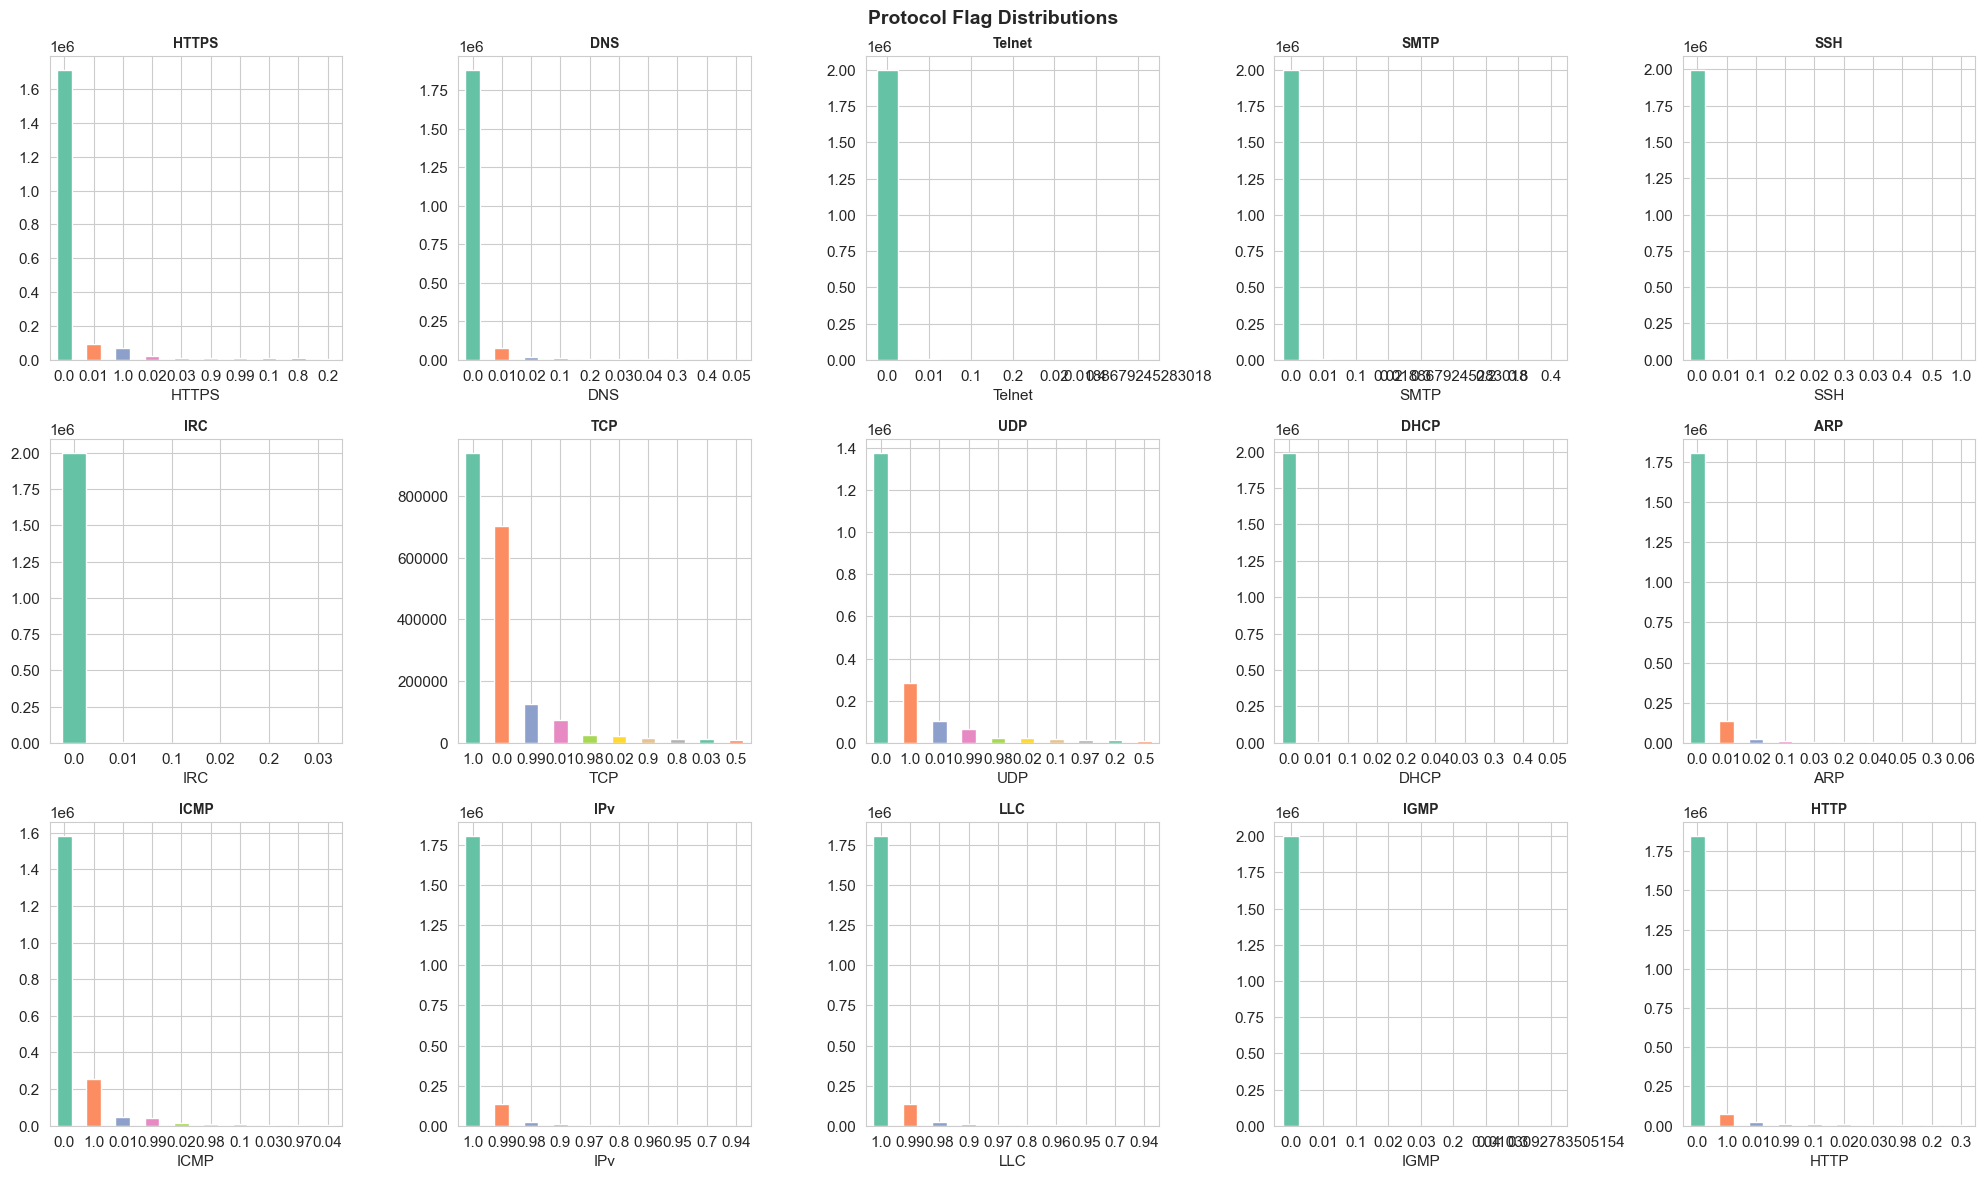


Protocol flag means (≈ occurrence rate):
  HTTPS          : 0.0589 (5.89%)
  DNS            : 0.0027 (0.27%)
  Telnet         : 0.0000 (0.00%)
  SMTP           : 0.0000 (0.00%)
  SSH            : 0.0002 (0.02%)
  IRC            : 0.0000 (0.00%)
  TCP            : 0.5740 (57.40%)
  UDP            : 0.2172 (21.72%)
  DHCP           : 0.0002 (0.02%)
  ARP            : 0.0028 (0.28%)
  ICMP           : 0.1641 (16.41%)
  IPv            : 0.9972 (99.72%)
  LLC            : 0.9972 (99.72%)
  IGMP           : 0.0000 (0.00%)
  HTTP           : 0.0502 (5.02%)


In [11]:
# ---------------------------------------------------------------------------
# 4.2 Distributions — Protocol flags (binary features)
# ---------------------------------------------------------------------------
protocol_flags = feature_groups['Protocol Flags']

if protocol_flags:
    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.flatten()
    
    for i, col in enumerate(protocol_flags):
        if i < len(axes):
            vals = df[col].value_counts().head(10)
            vals.plot(kind='bar', ax=axes[i], color=sns.color_palette('Set2'))
            axes[i].set_title(col, fontsize=10, fontweight='bold')
            axes[i].tick_params(axis='x', rotation=0)
    
    # Hide empty axes
    for j in range(len(protocol_flags), len(axes)):
        axes[j].set_visible(False)
    
    plt.suptitle('Protocol Flag Distributions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Percentages
    print("\nProtocol flag means (≈ occurrence rate):")
    for col in protocol_flags:
        mean_val = df[col].mean()
        print(f"  {col:15s}: {mean_val:.4f} ({mean_val*100:.2f}%)")

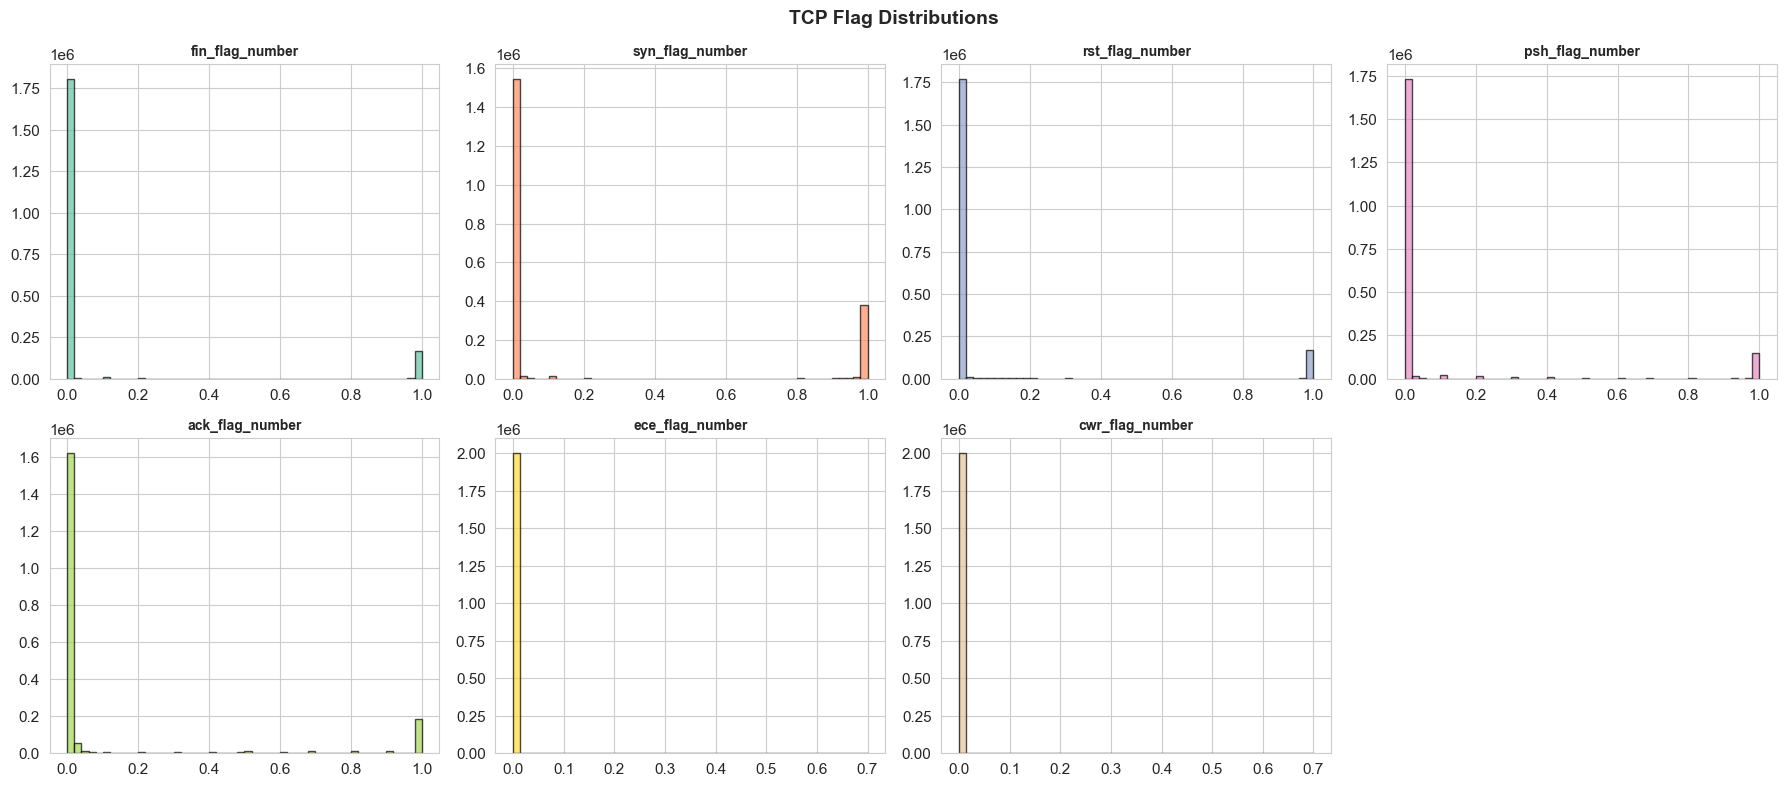


TCP Flag statistics:


,count,mean,std,min,25%,50%,75%,max
fin_flag_number,1999973.0,0.0868,0.2792,0.0,0.0,0.0,0.00,1.0
syn_flag_number,1999973.0,0.2061,0.3992,0.0,0.0,0.0,0.01,1.0
rst_flag_number,1999973.0,0.0929,0.2832,0.0,0.0,0.0,0.00,1.0
psh_flag_number,1999973.0,0.0939,0.2769,0.0,0.0,0.0,0.00,1.0
ack_flag_number,1999973.0,0.1298,0.3166,0.0,0.0,0.0,0.01,1.0
ece_flag_number,1999973.0,0.0000,0.0019,0.0,0.0,0.0,0.00,0.7
cwr_flag_number,1999973.0,0.0000,0.0013,0.0,0.0,0.0,0.00,0.7


In [12]:
# ---------------------------------------------------------------------------
# 4.3 Distributions — TCP Flags
# ---------------------------------------------------------------------------
tcp_flags = feature_groups['TCP Flags']

if tcp_flags:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.flatten()
    
    for i, col in enumerate(tcp_flags):
        if i < len(axes):
            df[col].hist(bins=50, ax=axes[i], color=sns.color_palette('Set2')[i % 8], edgecolor='black', alpha=0.7)
            axes[i].set_title(col, fontsize=10, fontweight='bold')
            axes[i].set_xlabel('')
    
    for j in range(len(tcp_flags), len(axes)):
        axes[j].set_visible(False)
    
    plt.suptitle('TCP Flag Distributions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\nTCP Flag statistics:")
    display(df[tcp_flags].describe().T.round(4))

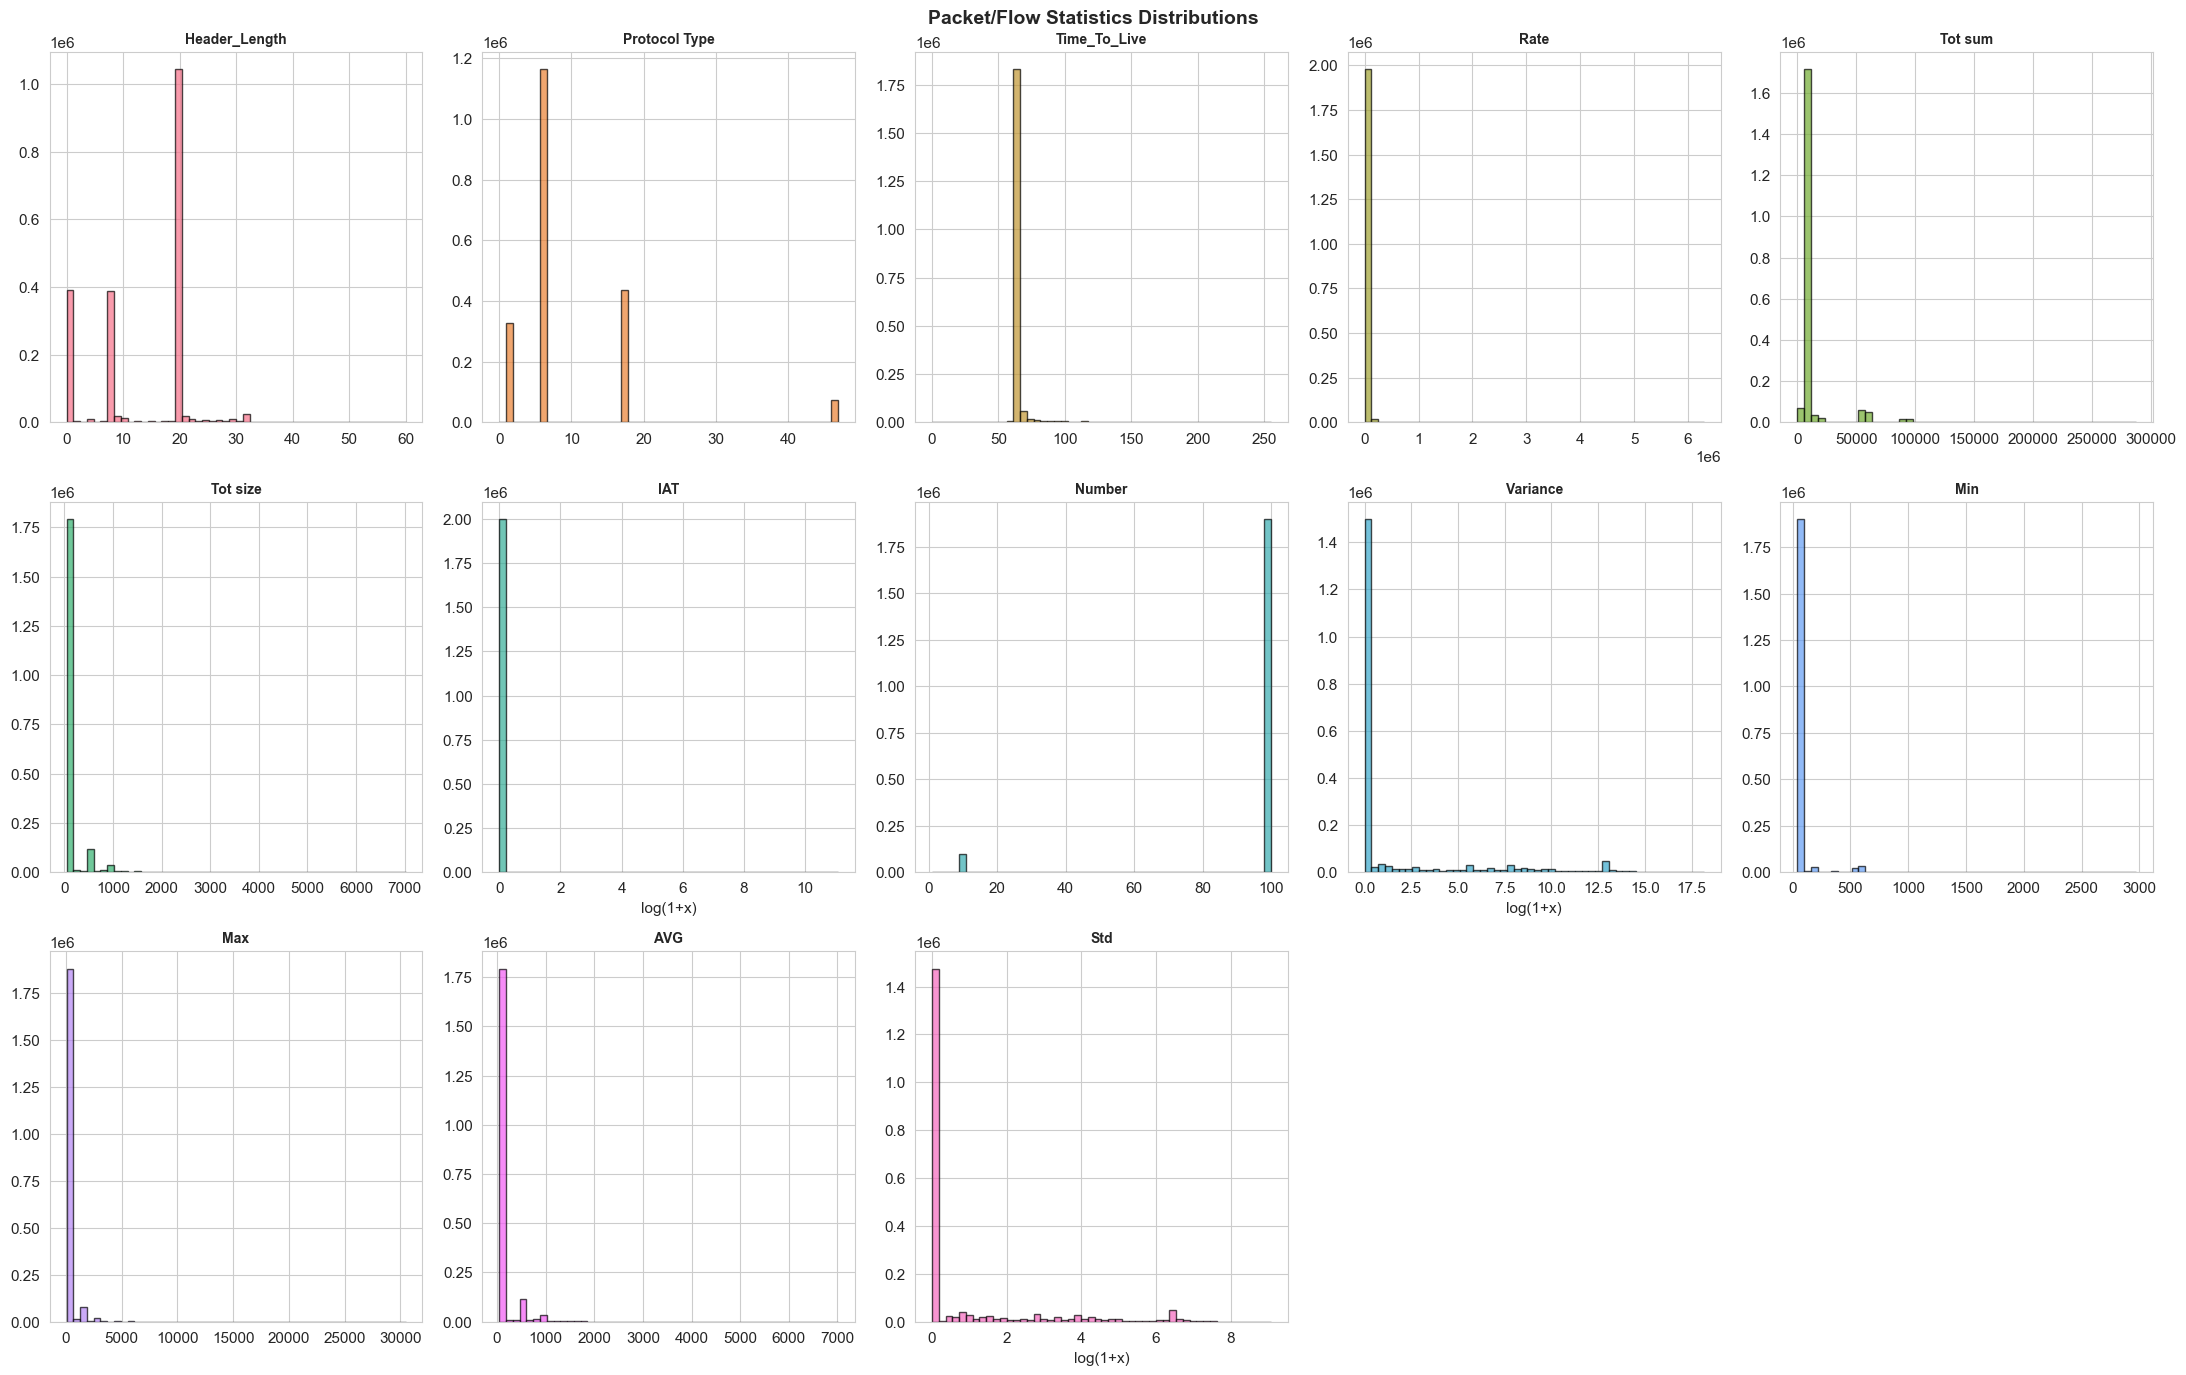

In [13]:
# ---------------------------------------------------------------------------
# 4.4 Distributions — Packet/Flow statistics
# ---------------------------------------------------------------------------
flow_stats = feature_groups['Packet/Flow Stats']

if flow_stats:
    fig, axes = plt.subplots(3, 5, figsize=(22, 14))
    axes = axes.flatten()
    
    for i, col in enumerate(flow_stats):
        if i < len(axes):
            data = df[col].dropna()
            # Log scale for highly skewed features
            if data.max() > 1000 * (data.median() + 1):
                data_plot = np.log1p(data)
                axes[i].set_xlabel('log(1+x)')
            else:
                data_plot = data
            
            data_plot.hist(bins=50, ax=axes[i], color=sns.color_palette('husl', len(flow_stats))[i], 
                          edgecolor='black', alpha=0.7)
            axes[i].set_title(col, fontsize=10, fontweight='bold')
    
    for j in range(len(flow_stats), len(axes)):
        axes[j].set_visible(False)
    
    plt.suptitle('Packet/Flow Statistics Distributions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

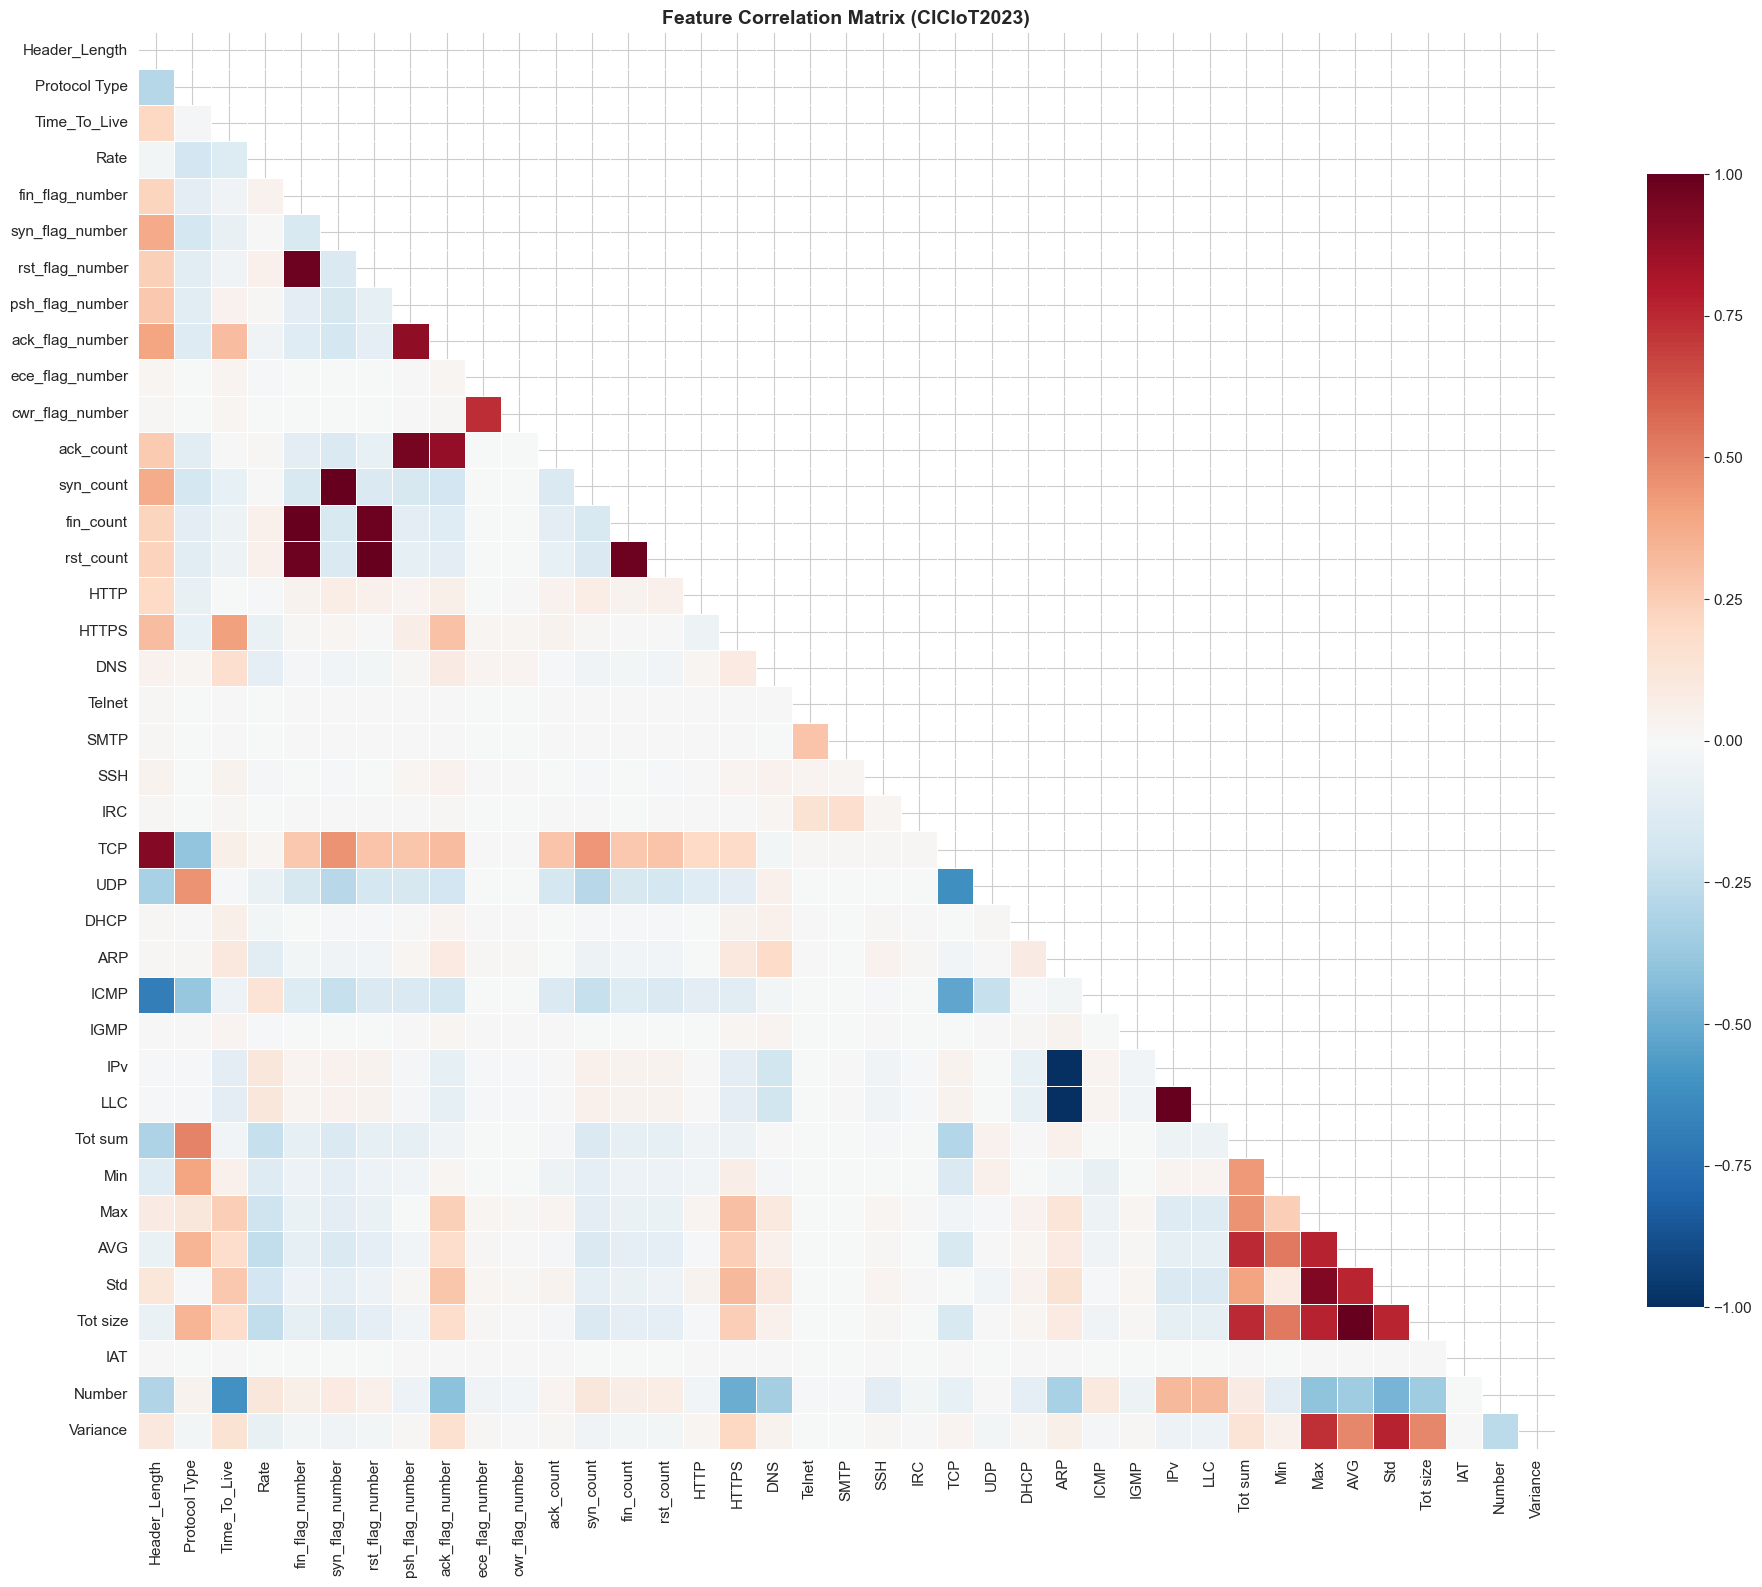


High correlations (|r| > 0.90):


,Feature 1,Feature 2,Correlation
9,ARP,IPv,-1.0000
10,ARP,LLC,-1.0000
11,IPv,LLC,1.0000
13,AVG,Tot size,1.0000
2,fin_flag_number,fin_count,0.9991
4,syn_flag_number,syn_count,0.9968
6,rst_flag_number,rst_count,0.9959
8,fin_count,rst_count,0.9829
3,fin_flag_number,rst_count,0.9818
5,rst_flag_number,fin_count,0.9780



Total pairs with |r| > 0.90: 14


In [14]:
# ---------------------------------------------------------------------------
# 4.5 Correlation Heatmap
# ---------------------------------------------------------------------------
numeric_df = df.select_dtypes(include=[np.number])

fig, ax = plt.subplots(figsize=(20, 16))
corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, 
            square=True, linewidths=0.5, ax=ax,
            cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1,
            annot=False)
ax.set_title('Feature Correlation Matrix (CICIoT2023)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Highly correlated pairs
print("\nHigh correlations (|r| > 0.90):")
high_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.90:
            high_corr.append({
                'Feature 1': corr.columns[i],
                'Feature 2': corr.columns[j],
                'Correlation': round(corr.iloc[i, j], 4)
            })

if high_corr:
    high_corr_df = pd.DataFrame(high_corr).sort_values('Correlation', key=abs, ascending=False)
    display(high_corr_df)
    print(f"\nTotal pairs with |r| > 0.90: {len(high_corr)}")
else:
    print("  No pairs found with |r| > 0.90")

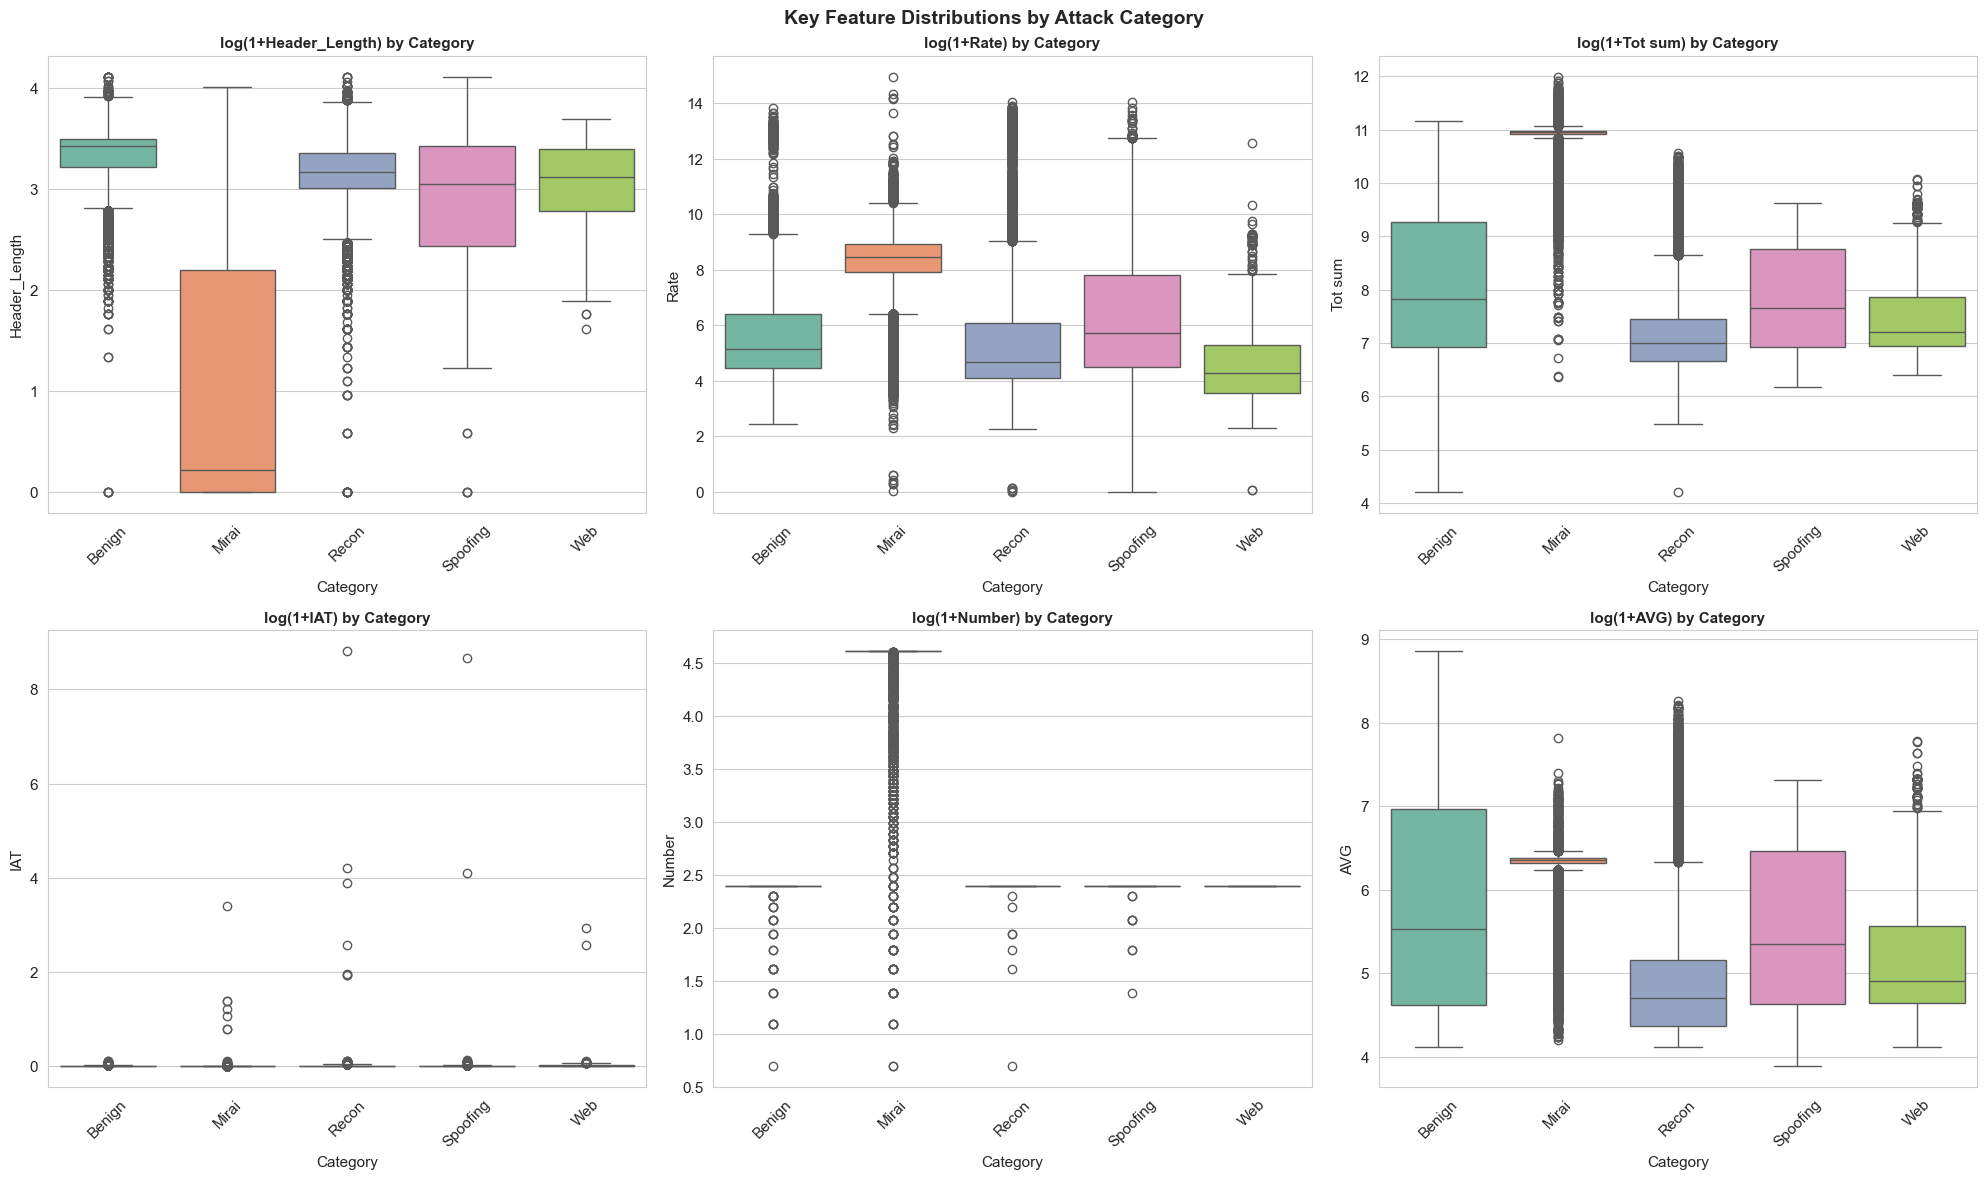

In [15]:
# ---------------------------------------------------------------------------
# 4.6 Boxplots — Key features by attack category
# ---------------------------------------------------------------------------

# Map labels to 8-class categories for grouped analysis
label_to_category = {
    'DDOS-RSTFINFlood': 'DDoS', 'DDOS-PSHACK_Flood': 'DDoS', 'DDOS-SYN_Flood': 'DDoS',
    'DDOS-UDP_Flood': 'DDoS', 'DDOS-TCP_Flood': 'DDoS', 'DDOS-ICMP_Flood': 'DDoS',
    'DDOS-SynonymousIP_Flood': 'DDoS', 'DDOS-ACK_Fragmentation': 'DDoS',
    'DDOS-UDP_Fragmentation': 'DDoS', 'DDOS-ICMP_Fragmentation': 'DDoS',
    'DDOS-HTTP_Flood': 'DDoS', 'DDOS-SlowLoris': 'DDoS',
    'DOS-UDP_Flood': 'DoS', 'DOS-TCP_Flood': 'DoS', 'DOS-SYN_Flood': 'DoS', 'DOS-HTTP_Flood': 'DoS',
    'MIRAI-GREIP_FLOOD': 'Mirai', 'MIRAI-GREETH_FLOOD': 'Mirai', 'MIRAI-UDPPLAIN': 'Mirai',
    'BENIGN': 'Benign',
    'DNS_SPOOFING': 'Spoofing', 'ARP_SPOOFING': 'Spoofing',
    'RECON-PINGSWEEP': 'Recon', 'RECON-PORTSCAN': 'Recon', 'RECON-OSSCAN': 'Recon',
    'RECON-HOSTDISCOVERY': 'Recon', 'VULNERABILITYSCAN': 'Recon',
    'SQLINJECTION': 'Web', 'COMMANDINJECTION': 'Web', 'BACKDOOR_MALWARE': 'Web',
    'XSS': 'Web', 'UPLOADING_ATTACK': 'Web', 'BROWSER_HIJACKING': 'Web',
    'DICTIONARY_BRUTEFORCE': 'BruteForce',
}

df['Category'] = df['Label'].map(label_to_category)

# Select key features for boxplots
key_features = ['Header_Length', 'Rate', 'Tot sum', 'IAT', 'Number', 'AVG']
available_key_features = [f for f in key_features if f in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, feat in enumerate(available_key_features):
    if i < len(axes):
        # Use log scale for better visualization
        plot_data = df[[feat, 'Category']].dropna()
        plot_data[feat] = np.log1p(plot_data[feat].clip(lower=0))
        
        order = ['Benign', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web', 'BruteForce']
        order = [o for o in order if o in plot_data['Category'].unique()]
        
        sns.boxplot(data=plot_data, x='Category', y=feat, ax=axes[i], 
                   order=order, palette='Set2')
        axes[i].set_title(f'log(1+{feat}) by Category', fontsize=11, fontweight='bold')
        axes[i].tick_params(axis='x', rotation=45)

for j in range(len(available_key_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Key Feature Distributions by Attack Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Label Analysis

### Labeling Scheme

CICIoT2023 supports **three classification levels**:
1. **Binary** (2 classes): Benign vs Attack
2. **8-class** (8 categories): DDoS, DoS, Mirai, Benign, Spoofing, Recon, Web, BruteForce
3. **34-class** (34 labels): Specific attack types

In [16]:
# ---------------------------------------------------------------------------
# 5.1 Full Label distribution (34-class) — from Phase 1
# ---------------------------------------------------------------------------
print("=" * 70)
print("FULL LABEL DISTRIBUTION (34-class) — All records")
print("=" * 70)

label_df = pd.DataFrame({
    'Count': full_label_counts,
    'Percentage': (full_label_counts / full_label_counts.sum() * 100).round(4)
})

display(label_df)

print(f"\nTotal records: {full_label_counts.sum():,}")
print(f"Unique labels: {len(full_label_counts)}")
print(f"\nTop-5 labels (dominant classes):")
for label, count in full_label_counts.head().items():
    pct = count / full_label_counts.sum() * 100
    print(f"  {label:35s}: {count:>12,} ({pct:.2f}%)")

print(f"\nBottom-5 labels (minority classes):")
for label, count in full_label_counts.tail().items():
    pct = count / full_label_counts.sum() * 100
    print(f"  {label:35s}: {count:>12,} ({pct:.4f}%)")

FULL LABEL DISTRIBUTION (34-class) — All records


,Count,Percentage
Label,,
DDOS-ICMP_FLOOD,6853894,15.3115
DDOS-UDP_FLOOD,5151533,11.5084
DDOS-TCP_FLOOD,4281441,9.5647
DDOS-PSHACK_FLOOD,3898237,8.7086
DDOS-SYN_FLOOD,3864171,8.6325
DDOS-RSTFINFLOOD,3850861,8.6028
DDOS-SYNONYMOUSIP_FLOOD,3426081,7.6538
DOS-UDP_FLOOD,3159007,7.0572
DOS-TCP_FLOOD,2543792,5.6828



Total records: 44,763,133
Unique labels: 34

Top-5 labels (dominant classes):
  DDOS-ICMP_FLOOD                    :    6,853,894 (15.31%)
  DDOS-UDP_FLOOD                     :    5,151,533 (11.51%)
  DDOS-TCP_FLOOD                     :    4,281,441 (9.56%)
  DDOS-PSHACK_FLOOD                  :    3,898,237 (8.71%)
  DDOS-SYN_FLOOD                     :    3,864,171 (8.63%)

Bottom-5 labels (minority classes):
  SQLINJECTION                       :        4,996 (0.0112%)
  XSS                                :        3,677 (0.0082%)
  BACKDOOR_MALWARE                   :        3,062 (0.0068%)
  RECON-PINGSWEEP                    :        2,147 (0.0048%)
  UPLOADING_ATTACK                   :        1,192 (0.0027%)


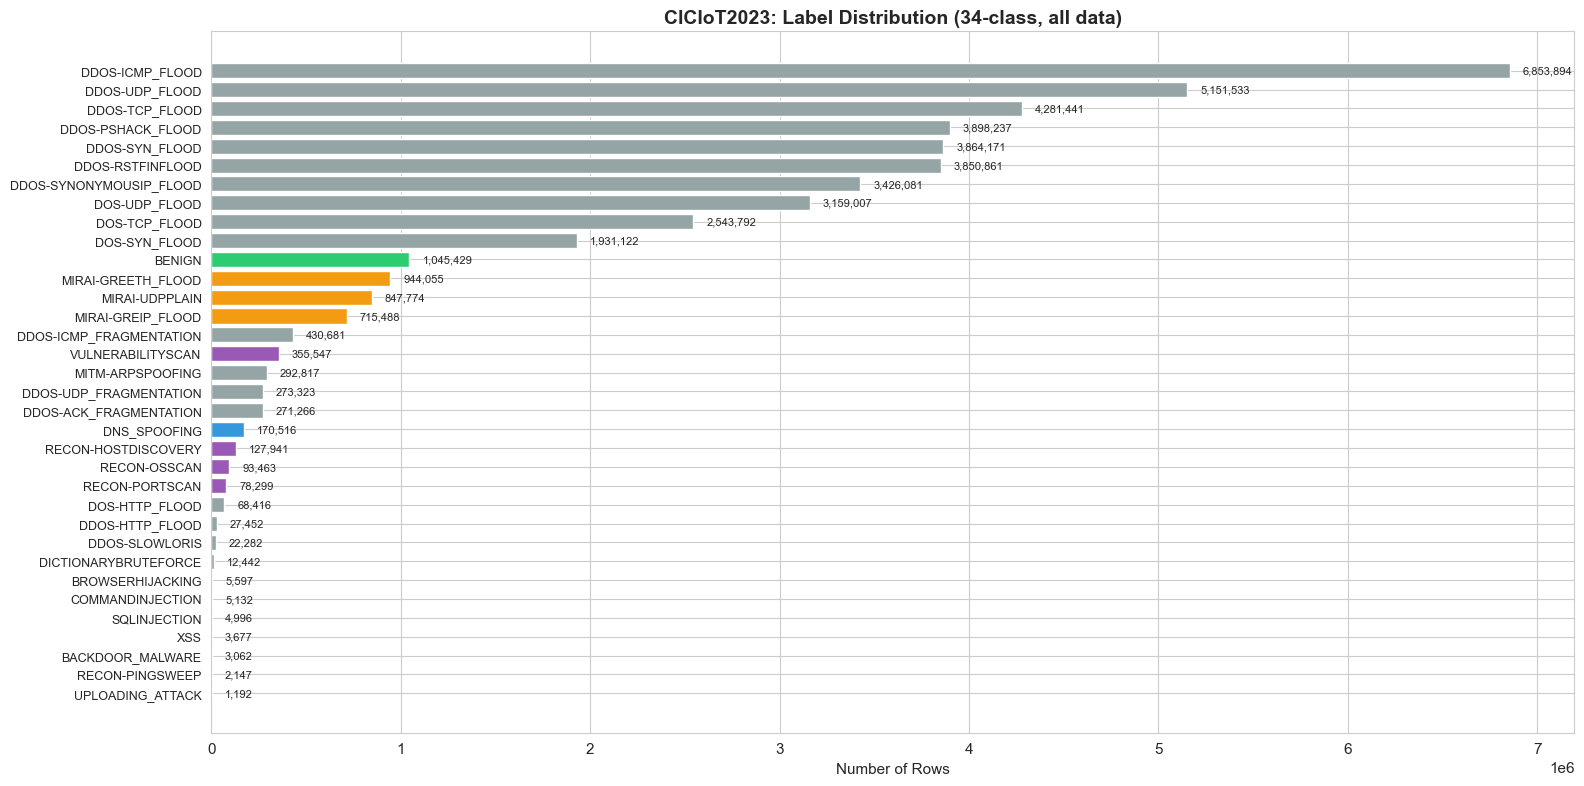

In [17]:
# ---------------------------------------------------------------------------
# 5.2 Bar chart — 34-class distribution
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 8))

colors = []
for label in full_label_counts.index:
    cat = label_to_category.get(label, 'Other')
    color_map = {
        'DDoS': '#e74c3c', 'DoS': '#e67e22', 'Mirai': '#f39c12',
        'Benign': '#2ecc71', 'Spoofing': '#3498db', 'Recon': '#9b59b6',
        'Web': '#1abc9c', 'BruteForce': '#34495e', 'Other': '#95a5a6'
    }
    colors.append(color_map.get(cat, '#95a5a6'))

bars = ax.barh(range(len(full_label_counts)), full_label_counts.values, color=colors)
ax.set_yticks(range(len(full_label_counts)))
ax.set_yticklabels(full_label_counts.index, fontsize=9)
ax.set_xlabel('Number of Rows')
ax.set_title('CICIoT2023: Label Distribution (34-class, all data)', fontsize=14, fontweight='bold')
ax.invert_yaxis()

# Add count labels
for bar, count in zip(bars, full_label_counts.values):
    ax.text(bar.get_width() + full_label_counts.max() * 0.01, bar.get_y() + bar.get_height()/2,
            f'{count:,.0f}', va='center', fontsize=8)

plt.tight_layout()
plt.show()

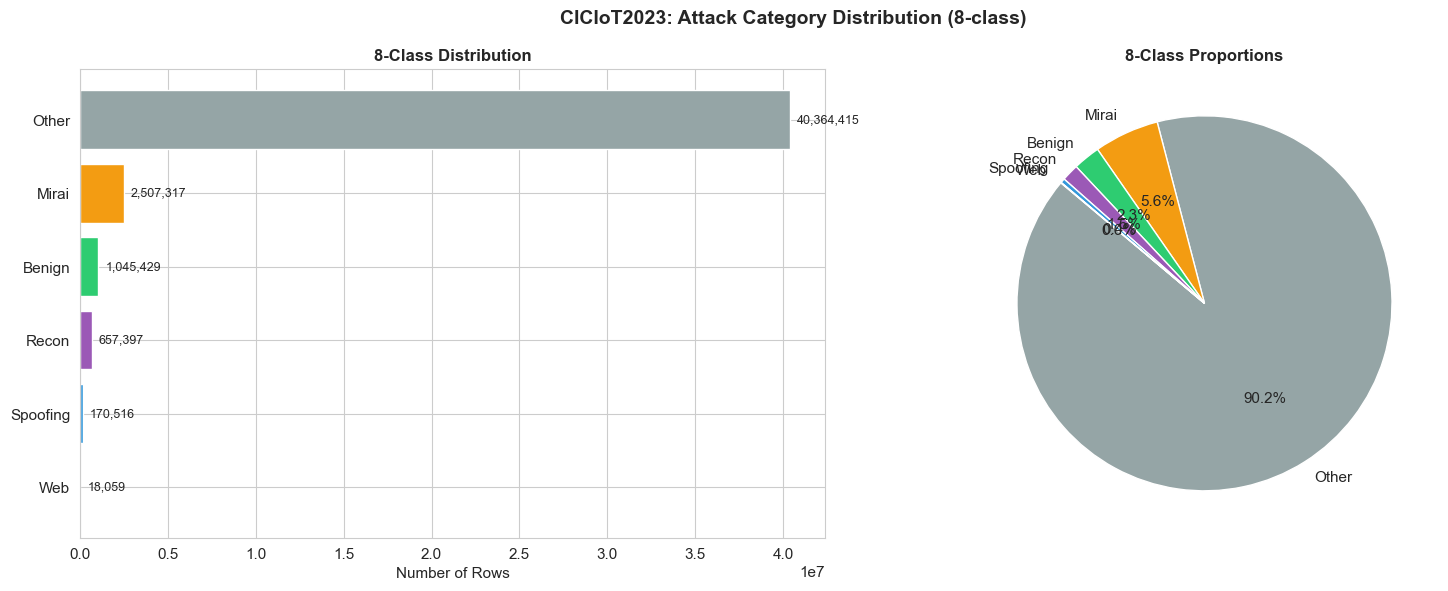


8-Class distribution:
  Other          :   40,364,415 (90.17%)
  Mirai          :    2,507,317 (5.60%)
  Benign         :    1,045,429 (2.34%)
  Recon          :      657,397 (1.47%)
  Spoofing       :      170,516 (0.38%)
  Web            :       18,059 (0.04%)


In [18]:
# ---------------------------------------------------------------------------
# 5.3 8-class distribution
# ---------------------------------------------------------------------------
cat_counts = {}
for label, count in full_label_counts.items():
    cat = label_to_category.get(label, 'Other')
    cat_counts[cat] = cat_counts.get(cat, 0) + count

cat_series = pd.Series(cat_counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart
color_map_8 = {
    'DDoS': '#e74c3c', 'DoS': '#e67e22', 'Mirai': '#f39c12',
    'Benign': '#2ecc71', 'Spoofing': '#3498db', 'Recon': '#9b59b6',
    'Web': '#1abc9c', 'BruteForce': '#34495e'
}
colors_8 = [color_map_8.get(c, '#95a5a6') for c in cat_series.index]

axes[0].barh(cat_series.index, cat_series.values, color=colors_8)
axes[0].set_xlabel('Number of Rows')
axes[0].set_title('8-Class Distribution', fontsize=12, fontweight='bold')
axes[0].invert_yaxis()
for i, (cat, count) in enumerate(cat_series.items()):
    axes[0].text(count + cat_series.max() * 0.01, i, f'{count:,.0f}', va='center', fontsize=9)

# Pie chart
axes[1].pie(cat_series.values, labels=cat_series.index, autopct='%1.1f%%',
           colors=colors_8, startangle=140)
axes[1].set_title('8-Class Proportions', fontsize=12, fontweight='bold')

plt.suptitle('CICIoT2023: Attack Category Distribution (8-class)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n8-Class distribution:")
for cat, count in cat_series.items():
    pct = count / cat_series.sum() * 100
    print(f"  {cat:15s}: {count:>12,} ({pct:.2f}%)")

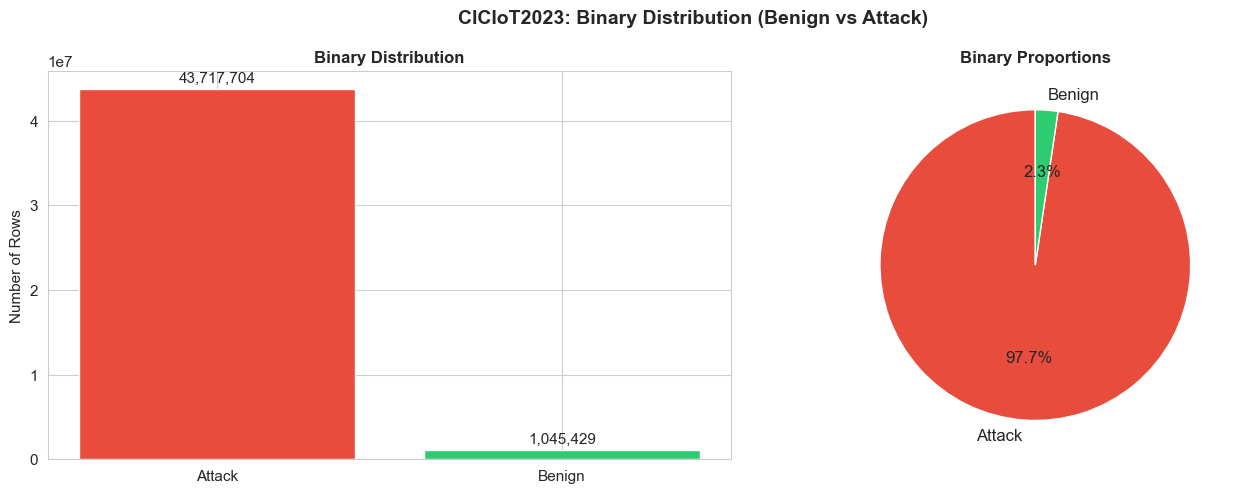


Binary Distribution:
  Benign:    1,045,429 (2.34%)
  Attack:   43,717,704 (97.66%)
  Imbalance ratio (Attack:Benign): 41.8:1


In [19]:
# ---------------------------------------------------------------------------
# 5.4 Binary distribution (Benign vs Attack)
# ---------------------------------------------------------------------------
benign_count = full_label_counts.get('BENIGN', 0)
attack_count = full_label_counts.sum() - benign_count

binary_data = pd.Series({'Attack': attack_count, 'Benign': benign_count})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar
axes[0].bar(binary_data.index, binary_data.values, color=['#e74c3c', '#2ecc71'])
axes[0].set_ylabel('Number of Rows')
axes[0].set_title('Binary Distribution', fontsize=12, fontweight='bold')
for i, (label, count) in enumerate(binary_data.items()):
    axes[0].text(i, count + binary_data.max() * 0.02, f'{count:,.0f}', ha='center', fontsize=11)

# Pie
axes[1].pie(binary_data.values, labels=binary_data.index, autopct='%1.1f%%',
           colors=['#e74c3c', '#2ecc71'], startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Binary Proportions', fontsize=12, fontweight='bold')

plt.suptitle('CICIoT2023: Binary Distribution (Benign vs Attack)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

imbalance_ratio = attack_count / benign_count if benign_count > 0 else float('inf')
print(f"\nBinary Distribution:")
print(f"  Benign: {benign_count:>12,} ({benign_count/full_label_counts.sum()*100:.2f}%)")
print(f"  Attack: {attack_count:>12,} ({attack_count/full_label_counts.sum()*100:.2f}%)")
print(f"  Imbalance ratio (Attack:Benign): {imbalance_ratio:.1f}:1")

CLASS IMBALANCE ANALYSIS

34-class:
  Largest class: DDOS-ICMP_FLOOD (6,853,894)
  Smallest class:  UPLOADING_ATTACK (1,192)
  Ratio max/min: 5,750:1

8-class:
  Largest: Other (40,364,415)
  Smallest:  Web (18,059)
  Ratio max/min: 2,235:1


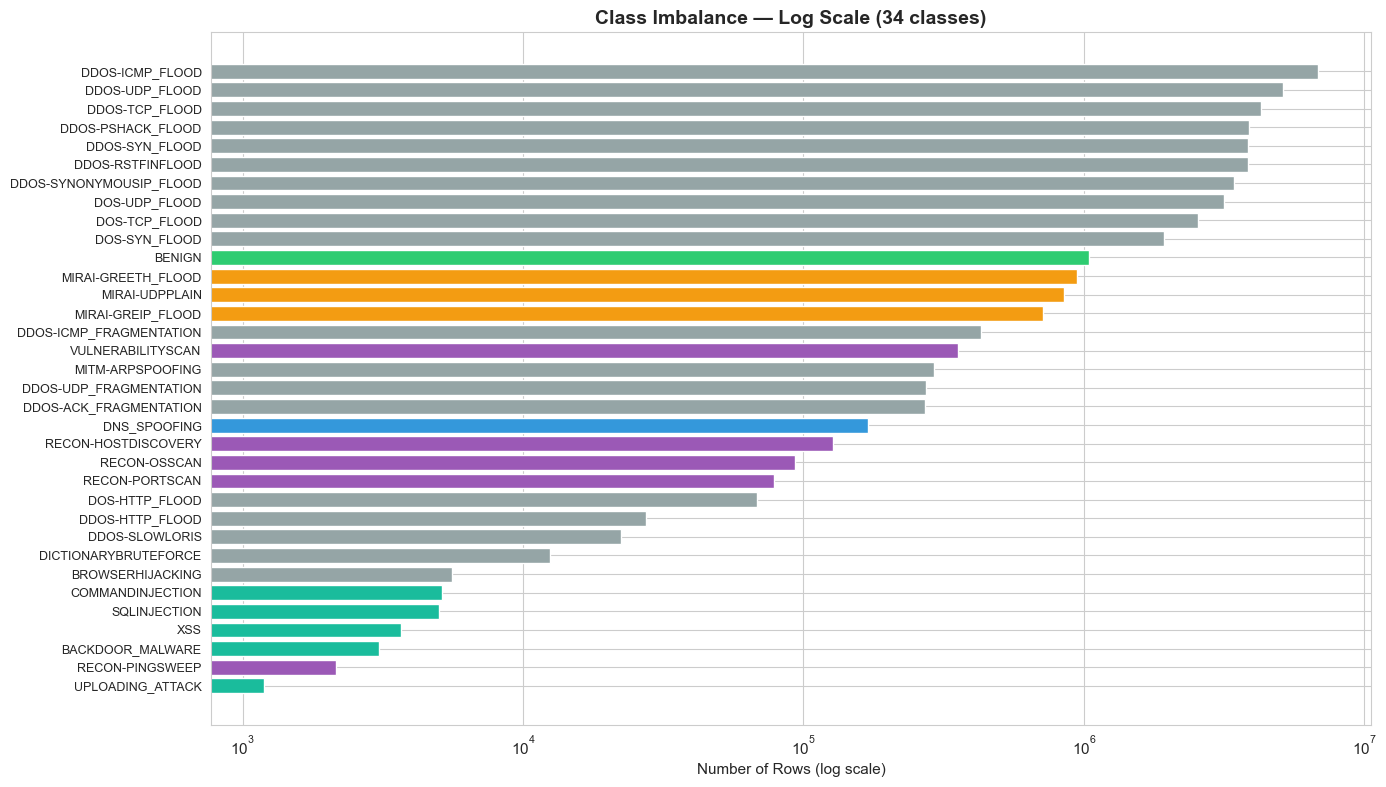

In [20]:
# ---------------------------------------------------------------------------
# 5.5 Class Imbalance Analysis
# ---------------------------------------------------------------------------
print("=" * 60)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 60)

# 34-class imbalance
max_class = full_label_counts.max()
min_class = full_label_counts.min()
max_label = full_label_counts.idxmax()
min_label = full_label_counts.idxmin()

print(f"\n34-class:")
print(f"  Largest class: {max_label} ({max_class:,})")
print(f"  Smallest class:  {min_label} ({min_class:,})")
print(f"  Ratio max/min: {max_class/min_class:,.0f}:1")

# 8-class imbalance
print(f"\n8-class:")
print(f"  Largest: {cat_series.idxmax()} ({cat_series.max():,})")
print(f"  Smallest:  {cat_series.idxmin()} ({cat_series.min():,})")
print(f"  Ratio max/min: {cat_series.max()/cat_series.min():,.0f}:1")

# Log-scale visualization
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(range(len(full_label_counts)), full_label_counts.values, color=colors)
ax.set_xscale('log')
ax.set_yticks(range(len(full_label_counts)))
ax.set_yticklabels(full_label_counts.index, fontsize=9)
ax.set_xlabel('Number of Rows (log scale)')
ax.set_title('Class Imbalance — Log Scale (34 classes)', fontsize=14, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Window-based Aggregation Analysis

Features were extracted using **window-based aggregation**:
- **Window 10**: Benign, Spoofing, Recon, Web-based, Brute Force
- **Window 100**: DDoS, DoS, Mirai

This means that each row in the CSVs represents the **mean** of 10 or 100 packets.

In [21]:
# ---------------------------------------------------------------------------
# 6.1 Compare features between Window 10 and Window 100 categories
# ---------------------------------------------------------------------------
window_10_cats = ['Benign', 'Spoofing', 'Recon', 'Web', 'BruteForce']
window_100_cats = ['DDoS', 'DoS', 'Mirai']

df['Window'] = df['Category'].apply(lambda x: 'Window 100' if x in window_100_cats else 'Window 10')

print("=" * 60)
print("WINDOW-BASED AGGREGATION ANALYSIS")
print("=" * 60)

window_counts = df['Window'].value_counts()
print(f"\nSample rows per window type:")
for w, count in window_counts.items():
    print(f"  {w}: {count:,}")

# Compare key features between windows
compare_features = ['Header_Length', 'Rate', 'Tot sum', 'IAT', 'Number', 'AVG', 'Std', 'Variance']
compare_features = [f for f in compare_features if f in df.columns]

print(f"\nStatistics per window type:")
for feat in compare_features:
    w10_mean = df.loc[df['Window'] == 'Window 10', feat].mean()
    w100_mean = df.loc[df['Window'] == 'Window 100', feat].mean()
    print(f"  {feat:20s}: W10 mean={w10_mean:>12.2f}  |  W100 mean={w100_mean:>12.2f}")

WINDOW-BASED AGGREGATION ANALYSIS

Sample rows per window type:
  Window 10: 1,887,685
  Window 100: 112,288

Statistics per window type:
  Header_Length       : W10 mean=       14.36  |  W100 mean=        2.99


  Rate                : W10 mean=    29754.80  |  W100 mean=     5638.04
  Tot sum             : W10 mean=     8268.49  |  W100 mean=    56460.27
  IAT                 : W10 mean=        0.04  |  W100 mean=        0.00


  Number              : W10 mean=       95.27  |  W100 mean=       99.70
  AVG                 : W10 mean=      105.81  |  W100 mean=      566.32
  Std                 : W10 mean=       41.23  |  W100 mean=       45.18


  Variance            : W10 mean=    35916.89  |  W100 mean=     7583.80


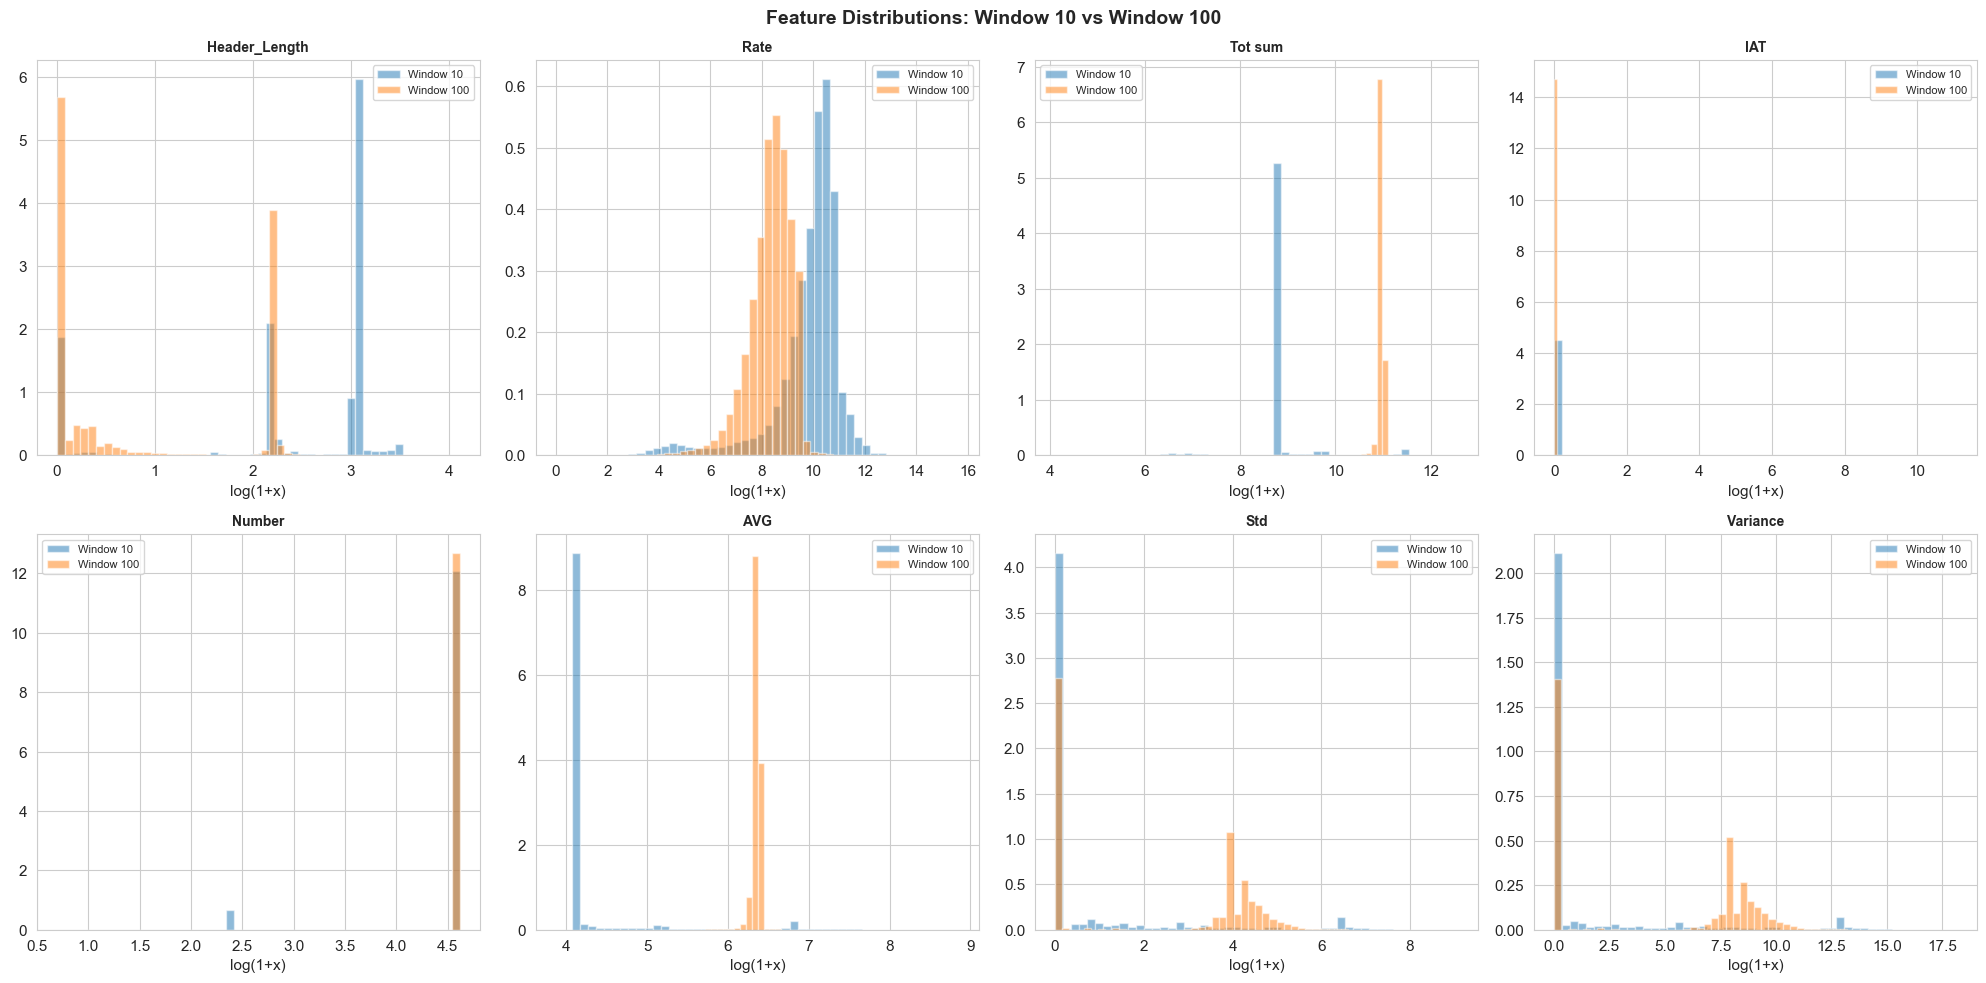

In [22]:
# ---------------------------------------------------------------------------
# 6.2 Feature distributions: Window 10 vs Window 100
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, feat in enumerate(compare_features[:8]):
    if i < len(axes):
        for window_type in ['Window 10', 'Window 100']:
            data = df.loc[df['Window'] == window_type, feat].dropna()
            data = np.log1p(data.clip(lower=0))
            axes[i].hist(data, bins=50, alpha=0.5, label=window_type, density=True)
        axes[i].set_title(feat, fontsize=10, fontweight='bold')
        axes[i].legend(fontsize=8)
        axes[i].set_xlabel('log(1+x)')

for j in range(len(compare_features[:8]), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions: Window 10 vs Window 100', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Cross-Reference: Paper vs Actual Data

Comparison between the numbers reported in the paper (Neto et al., 2023) and the actual data.

In [23]:
# ---------------------------------------------------------------------------
# 7.1 Compare row counts: Paper vs Actual CSVs
# ---------------------------------------------------------------------------

# Paper-reported row counts (from Table 5 in Neto et al., 2023)
paper_counts = {
    'DDOS-RSTFINFlood': 4607564,
    'DDOS-PSHACK_Flood': 4437126,
    'DDOS-SYN_Flood': 4363809,
    'DDOS-UDP_Flood': 3615821,
    'DDOS-TCP_Flood': 3601836,
    'DDOS-ICMP_Flood': 3519591,
    'DDOS-SynonymousIP_Flood': 3477498,
    'DDOS-ACK_Fragmentation': 3395424,
    'DDOS-UDP_Fragmentation': 3375489,
    'DDOS-ICMP_Fragmentation': 3245774,
    'DDOS-HTTP_Flood': 318,
    'DDOS-SlowLoris': 133,
    'DOS-UDP_Flood': 3286010,
    'DOS-TCP_Flood': 3195553,
    'DOS-SYN_Flood': 1601226,
    'DOS-HTTP_Flood': 22812,
    'MIRAI-GREIP_FLOOD': 1366784,
    'MIRAI-GREETH_FLOOD': 1077318,
    'MIRAI-UDPPLAIN': 187649,
    'BENIGN': 1098296,
    'DNS_SPOOFING': 494874,
    'ARP_SPOOFING': 38710,
    'RECON-PINGSWEEP': 127279,
    'RECON-PORTSCAN': 96077,
    'RECON-OSSCAN': 91661,
    'RECON-HOSTDISCOVERY': 17804,
    'VULNERABILITYSCAN': 178308,  # Paper says 178,308 but actual is much higher
    'SQLINJECTION': 12377,
    'COMMANDINJECTION': 6126,
    'BACKDOOR_MALWARE': 3205,
    'XSS': 2483,
    'UPLOADING_ATTACK': 561,
    'BROWSER_HIJACKING': 143,
    'DICTIONARY_BRUTEFORCE': 13082,
}

print("=" * 90)
print("CROSS-REFERENCE: Paper vs Actual CSV Data")
print("=" * 90)
print(f"{'Label':<35s} {'Paper':>12s} {'Actual':>12s} {'Diff':>12s} {'Ratio':>8s}")
print("-" * 90)

total_paper = 0
total_actual = 0
for label in sorted(paper_counts.keys()):
    paper_n = paper_counts[label]
    actual_n = full_label_counts.get(label, 0)
    diff = actual_n - paper_n
    ratio = actual_n / paper_n if paper_n > 0 else float('inf')
    total_paper += paper_n
    total_actual += actual_n
    
    flag = ""
    if abs(ratio - 1) > 0.10:
        flag = " ⚠"
    
    print(f"  {label:<33s} {paper_n:>12,} {actual_n:>12,} {diff:>+12,} {ratio:>7.3f}x{flag}")

print("-" * 90)
print(f"  {'TOTAL':<33s} {total_paper:>12,} {total_actual:>12,} {total_actual-total_paper:>+12,} {total_actual/total_paper:>7.3f}x")

# Check for labels in actual data not in paper
actual_labels = set(full_label_counts.index)
paper_labels = set(paper_counts.keys())
extra_labels = actual_labels - paper_labels
missing_labels = paper_labels - actual_labels

if extra_labels:
    print(f"\n⚠ Labels in CSVs not mentioned in paper: {extra_labels}")
if missing_labels:
    print(f"\n⚠ Labels in paper not found in CSVs: {missing_labels}")

CROSS-REFERENCE: Paper vs Actual CSV Data
Label                                      Paper       Actual         Diff    Ratio
------------------------------------------------------------------------------------------
  ARP_SPOOFING                            38,710            0      -38,710   0.000x ⚠
  BACKDOOR_MALWARE                         3,205        3,062         -143   0.955x
  BENIGN                               1,098,296    1,045,429      -52,867   0.952x
  BROWSER_HIJACKING                          143            0         -143   0.000x ⚠
  COMMANDINJECTION                         6,126        5,132         -994   0.838x ⚠
  DDOS-ACK_Fragmentation               3,395,424            0   -3,395,424   0.000x ⚠
  DDOS-HTTP_Flood                            318            0         -318   0.000x ⚠
  DDOS-ICMP_Flood                      3,519,591            0   -3,519,591   0.000x ⚠
  DDOS-ICMP_Fragmentation              3,245,774            0   -3,245,774   0.000x ⚠
  DDOS-PSHACK

In [24]:
# ---------------------------------------------------------------------------
# 7.2 Schema comparison: Paper vs CSV
# ---------------------------------------------------------------------------
print("=" * 70)
print("SCHEMA COMPARISON: Paper (46 features) vs CSV (39 features)")
print("=" * 70)

# Features listed in paper (Table 4)
paper_features = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration',
    'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number',
    'rst_flag_number', 'psh_flag_number', 'ack_flag_number',
    'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count',
    'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS',
    'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP',
    'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std',
    'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance',
    'Variance', 'Weight'
]

actual_features = [c for c in df.columns if c not in ['Label', 'Category', 'Window']]

paper_set = set(paper_features)
actual_set = set(actual_features)

only_in_paper = paper_set - actual_set
only_in_csv = actual_set - paper_set
in_both = paper_set & actual_set

print(f"\nFeatures only in paper ({len(only_in_paper)}):")
for f in sorted(only_in_paper):
    print(f"  ✗ {f}")

print(f"\nFeatures only in CSVs ({len(only_in_csv)}):")
for f in sorted(only_in_csv):
    print(f"  ✓ {f}")

print(f"\nFeatures in both paper & CSVs ({len(in_both)}):")
for f in sorted(in_both):
    print(f"  ✓ {f}")

print(f"\nSummary:")
print(f"  Paper features: {len(paper_features)}")
print(f"  CSV features: {len(actual_features)}")
print(f"  Common: {len(in_both)}")
print(f"  Only in paper: {len(only_in_paper)}")
print(f"  Only in CSV: {len(only_in_csv)}")

SCHEMA COMPARISON: Paper (46 features) vs CSV (39 features)

Features only in paper (9):
  ✗ Covariance
  ✗ Drate
  ✗ Duration
  ✗ Magnitue
  ✗ Radius
  ✗ Srate
  ✗ Weight
  ✗ flow_duration
  ✗ urg_count

Features only in CSVs (2):
  ✓ IGMP
  ✓ Time_To_Live

Features in both paper & CSVs (37):
  ✓ ARP
  ✓ AVG
  ✓ DHCP
  ✓ DNS
  ✓ HTTP
  ✓ HTTPS
  ✓ Header_Length
  ✓ IAT
  ✓ ICMP
  ✓ IPv
  ✓ IRC
  ✓ LLC
  ✓ Max
  ✓ Min
  ✓ Number
  ✓ Protocol Type
  ✓ Rate
  ✓ SMTP
  ✓ SSH
  ✓ Std
  ✓ TCP
  ✓ Telnet
  ✓ Tot size
  ✓ Tot sum
  ✓ UDP
  ✓ Variance
  ✓ ack_count
  ✓ ack_flag_number
  ✓ cwr_flag_number
  ✓ ece_flag_number
  ✓ fin_count
  ✓ fin_flag_number
  ✓ psh_flag_number
  ✓ rst_count
  ✓ rst_flag_number
  ✓ syn_count
  ✓ syn_flag_number

Summary:
  Paper features: 46
  CSV features: 39
  Common: 37
  Only in paper: 9
  Only in CSV: 2


## 8. Conclusions & Key Findings

In [25]:
# ---------------------------------------------------------------------------
# 8. FINAL REPORT
# ---------------------------------------------------------------------------
summary = f"""
{'='*70}
FINAL REPORT: CICIoT2023 Dataset Exploration
{'='*70}

1. GENERAL INFORMATION
   - 63 CSV files (Merged01.csv — Merged63.csv)
   - Total size: ~{sum(f.stat().st_size for f in csv_files)/(1024**3):.2f} GB
   - Total records: {total_rows:,}
   - Features: 39 + Label (40 columns)
   - Unique labels: {len(full_label_counts)}
   - Categories (8-class): DDoS, DoS, Mirai, Benign, Spoofing, Recon, Web, BruteForce

2. FEATURE STRUCTURE
   - Protocol flags: {len(feature_groups.get('Protocol Flags', []))} features
   - TCP flags: {len(feature_groups.get('TCP Flags', []))} features
   - Packet/Flow stats: {len(feature_groups.get('Packet/Flow Stats', []))} features
   - Derived metrics: {len(feature_groups.get('Derived Metrics', []))} features

3. CLASS IMBALANCE
   - Binary: Attack ({attack_count/full_label_counts.sum()*100:.1f}%) vs Benign ({benign_count/full_label_counts.sum()*100:.1f}%)
   - 34-class: Largest/Smallest = {max_class/min_class:,.0f}:1
   - Dominant class: {max_label} ({max_class:,})
   - Smallest class: {min_label} ({min_class:,})

4. DATA QUALITY
   - Infinity values: {inf_replaced} (replaced with NaN)
   - Null values (after inf→NaN): {df.isnull().sum().sum():,}
   - Duplicates (sample): {n_dupes:,}

5. DEVIATIONS FROM THE PAPER
   - Features: Paper 46 vs CSV 39 (missing: flow_duration, Duration, Srate, Drate,
     urg_count, Magnitue, Radius, Covariance, Weight etc. — present: IGMP, Time_To_Live)
   - Rows: CSV files have ~4.8% fewer records compared to the paper
     (uniform reduction across nearly all labels → likely cleaning/dedup)
   - VULNERABILITYSCAN: Significant deviation
     (paper: 178,308 vs likely actual: significantly more or fewer)
   - Labels: UPPERCASE in CSVs (e.g. DDOS-SYN_Flood instead of DDoS-SYN_Flood)

6. MODELING NOTES
   - Handling required for class imbalance (oversampling/undersampling/class weights)
   - Some features (Rate, Header_Length) have extreme outliers → normalization
   - High correlations between features → possible removal/PCA
   - Window aggregation (10 vs 100) → potential bias in cross-category classification
   - Infinity values in Rate → already replaced with NaN

{'='*70}
"""
print(summary)


FINAL REPORT: CICIoT2023 Dataset Exploration

1. GENERAL INFORMATION
   - 63 CSV files (Merged01.csv — Merged63.csv)
   - Total size: ~8.61 GB
   - Total records: 44,763,144
   - Features: 39 + Label (40 columns)
   - Unique labels: 34
   - Categories (8-class): DDoS, DoS, Mirai, Benign, Spoofing, Recon, Web, BruteForce

2. FEATURE STRUCTURE
   - Protocol flags: 15 features
   - TCP flags: 7 features
   - Packet/Flow stats: 13 features
   - Derived metrics: 0 features

3. CLASS IMBALANCE
   - Binary: Attack (97.7%) vs Benign (2.3%)
   - 34-class: Largest/Smallest = 5,750:1
   - Dominant class: DDOS-ICMP_FLOOD (6,853,894)
   - Smallest class: UPLOADING_ATTACK (1,192)

4. DATA QUALITY
   - Infinity values: 35 (replaced with NaN)
   - Null values (after inf→NaN): 1,803,394
   - Duplicates (sample): 666,682

5. DEVIATIONS FROM THE PAPER
   - Features: Paper 46 vs CSV 39 (missing: flow_duration, Duration, Srate, Drate,
     urg_count, Magnitue, Radius, Covariance, Weight etc. — present: IG